# **NFL Big Data Bowl 2027**

**Research Project: Combine to NFL Performance**

`1. Research Objective`
   To investigate whether movement characteristics captured through NFL Combine tracking sensors provide useful information about subsequent NFL regular-season performance.

`2. Central Research Question`
   Do movement characteristics captured by 10 Hz tracking sensors during NFL Scouting Combine drills provide useful information about a player's subsequent NFL regular-season performance beyond traditional Combine measurements?

`3. Initial Research Approach`
   - Understand the available datasets.
   - Identify relevant player information and tracking measurements.
   - Investigate relationships between Combine characteristics and NFL performance.
   - Evaluate whether sensor-derived features provide additional predictive information.

`Scope of This Notebook`
This notebook documents the initial data-understanding and exploratory-analysis stage. We begin with the available datasets, define an initial subgroup (wide receivers), and explore 40-yard-dash tracking records before creating event-level movement features. These steps establish a reliable foundation for later analysis of Combine movement characteristics and NFL career outcomes.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [3]:
# Get the current working directory
current_dir = Path.cwd()

# Move one level up to the project root
project_dir = current_dir.parent

# Locate the data folder
data_dir = project_dir / "data"

print("Current directory:", current_dir)
print("Project directory:", project_dir)
print("Data directory:", data_dir)

Current directory: c:\Users\User\OneDrive\Desktop\NFL_Big_Data_Bowl_2027\notebooks
Project directory: c:\Users\User\OneDrive\Desktop\NFL_Big_Data_Bowl_2027
Data directory: c:\Users\User\OneDrive\Desktop\NFL_Big_Data_Bowl_2027\data


##  **Players Dataset ( investigation)**

### **1. Players Dataset — Initial Data Understanding**

`**Research question:**` What information is available about the players in the competition dataset, and how complete and reliable are the player identifiers and basic player attributes?

`**Why are we investigating this?**`

Before combining information from different datasets, we need to understand the player records, identify the variables available, check the structure of the dataset, and determine whether player identifiers can reliably connect records across files. The `nfl_id` will be particularly important because player names alone may not uniquely identify individuals.

We will begin by examining the dataset's dimensions, columns, data types, summary statistics, duplicate records, missing values, and draft-related information.

In [4]:
players = pd.read_csv(data_dir / "players.csv")

In [5]:
players.head()

,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
0,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1.0,3.0,3.0
1,55870,Paris Johnson,2023,T,2001-07-31,Ohio State,Big Ten Conference,1.0,6.0,6.0
2,55874,Darnell Wright,2023,T,2001-08-10,Tennessee,Southeastern Conference,1.0,10.0,10.0
3,55875,Peter Skoronski,2023,G,2001-07-31,Northwestern,Big Ten Conference,1.0,11.0,11.0
4,55877,Lukas Van Ness,2023,DE,2001-07-06,Iowa,Big Ten Conference,1.0,13.0,13.0


In [6]:
players.shape

(510, 10)

In [7]:
players.info()

<class 'pandas.DataFrame'>
RangeIndex: 510 entries, 0 to 509
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   nfl_id                   510 non-null    int64  
 1   display_name             510 non-null    str    
 2   draft_year               510 non-null    int64  
 3   nfl_position             510 non-null    str    
 4   birth_date               510 non-null    str    
 5   college_name             510 non-null    str    
 6   college_conference       510 non-null    str    
 7   draft_round              383 non-null    float64
 8   draft_pick_within_round  383 non-null    float64
 9   draft_overall_pick       383 non-null    float64
dtypes: float64(3), int64(2), str(5)
memory usage: 40.0 KB


- `.info()` will give us structural information about our data set ,,, in which it will tell us non-null values, 
by which we can find is there any null value in particular column,,,, and it will tell us data types in our data set.

- By analyzing we foud that column `7, 8, 9` contains some missing values `( 510 - 383 = 127)` but by we can not assume wee will verify them 

- Looked at the competition dataset description: They explicitly states that these draft fields are null for Undrafted Free Agents (UDFAs).

**This is an important distinction:**
- Missing because information was not recorded.
- Missing because the information does not apply.

In [8]:
players.describe()

,nfl_id,draft_year,draft_round,draft_pick_within_round,draft_overall_pick
count,510.000000,510.000000,383.000000,383.000000,383.000000
mean,57331.319608,2024.025490,4.101828,19.475196,126.535248
std,979.506689,0.808439,1.913734,11.184497,72.197252
min,55867.000000,2023.000000,1.000000,1.000000,3.000000
25%,56273.500000,2023.000000,2.000000,10.000000,63.500000
50%,57290.000000,2024.000000,4.000000,20.000000,122.000000
75%,58302.750000,2025.000000,6.000000,28.500000,186.000000
max,59278.000000,2025.000000,7.000000,43.000000,257.000000


- `.describe()`  used to generate summary statistics for numerical columns in the players dataset.

**Observations:**
1. The dataset contains 510 player records.

2. Draft-related columns contain 383 non-missing values.

3. Draft rounds range from 1 to 7.

4. The median overall draft pick is 122.

- These statistics help us understand the distribution of numerical variables. However, identifiers such as nfl_id should not be interpreted as meaningful numerical measurements.

In [9]:
players.describe(include="all")

,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
count,510.000000,510,510.000000,510,510,510,510,383.000000,383.000000,383.000000
unique,NaN,508,NaN,17,441,112,21,NaN,NaN,NaN
top,NaN,Anthony Johnson,NaN,WR,2001-05-03,Georgia,Southeastern Conference,NaN,NaN,NaN
freq,NaN,2,NaN,106,4,22,142,NaN,NaN,NaN
mean,57331.319608,NaN,2024.025490,NaN,NaN,NaN,NaN,4.101828,19.475196,126.535248
std,979.506689,NaN,0.808439,NaN,NaN,NaN,NaN,1.913734,11.184497,72.197252
min,55867.000000,NaN,2023.000000,NaN,NaN,NaN,NaN,1.000000,1.000000,3.000000
25%,56273.500000,NaN,2023.000000,NaN,NaN,NaN,NaN,2.000000,10.000000,63.500000
50%,57290.000000,NaN,2024.000000,NaN,NaN,NaN,NaN,4.000000,20.000000,122.000000
75%,58302.750000,NaN,2025.000000,NaN,NaN,NaN,NaN,6.000000,28.500000,186.000000


**Checking Player-ID Uniqueness and Name Duplicates**

 `Question:` Is `nfl_id` unique, and do player names uniquely identify records?

 `Why:` Names may repeat, so we need to verify which field is safe for matching datasets.**

In [10]:
players["nfl_id"].nunique()

510

In [11]:
players["display_name"].value_counts().head(10)

display_name
Anthony Johnson       2
Leonard Taylor        2
Will Anderson         1
Paris Johnson         1
Darnell Wright        1
Peter Skoronski       1
Lukas Van Ness        1
Broderick Jones       1
Will McDonald         1
Jaxon Smith-Njigba    1
Name: count, dtype: int64

- Column	        :   nfl_id	|     display_name
- Total records   :	 510	|       510	
- Unique values   :    510    |       508


**Conclusion:**
- Two different `NFL IDs` can have the same display name. 
- A player's name alone is therefore not reliable enough to identify them.

In [12]:
players[players["display_name"].duplicated(keep=False)]

,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
108,56107,Anthony Johnson,2023,FS,1999-12-02,Iowa State,Big Twelve Conference,7.0,25.0,242.0
131,56629,Anthony Johnson,2023,CB,1999-06-12,Virginia,Atlantic Coast Conference,NaN,NaN,NaN
134,56363,Leonard Taylor,2023,TE,1999-08-26,Cincinnati,Big Twelve Conference,NaN,NaN,NaN
301,57434,Leonard Taylor,2024,DT,2002-05-29,Miami,Atlantic Coast Conference,NaN,NaN,NaN


- We found that the names appearing twice are not duplicate records but they are of different players with same name , we can same name with 
  different `DOB / different Position / different college name`.
- Also there is `NaN` placholder which means the dataset does not currently provide a value for these particular cells.
- We cannot immediately conclude that a player was not drafted. The value may be missing for other reasons.

In [13]:
players["nfl_id"].duplicated().sum()

np.int64(0)

**Investigating Missing Player Information**

`Question:` Which player attributes contain missing values, and how many records are affected?

`Why:` Missingness can affect later filtering and comparisons. We should identify it before deciding how to handle it.

In [14]:
players.isnull().sum()

nfl_id                       0
display_name                 0
draft_year                   0
nfl_position                 0
birth_date                   0
college_name                 0
college_conference           0
draft_round                127
draft_pick_within_round    127
draft_overall_pick         127
dtype: int64

In [15]:
players[
    ["draft_round", "draft_pick_within_round", "draft_overall_pick"]
].isnull().sum(axis=1).value_counts()

0    383
3    127
Name: count, dtype: int64

**Missing Value Analysis — Players Dataset**

- Total player records: 510.
- Three draft-related columns contain 127 missing values each:
  
  - `draft_round`
  
  - `draft_pick_within_round`
  
  - `draft_overall_pick`

**Finding:** A row-wise missing-value analysis showed that 383 players have all three draft values available, while 127 players have all three values missing.

**Interpretation:** The missing values occur together in these three columns. However, we cannot yet determine why the information is missing or conclude that these players were not drafted.

In [16]:
players.loc[
    players["draft_round"].isnull(),
    ["nfl_id", "display_name", "draft_year", "nfl_position"]
]

,nfl_id,display_name,draft_year,nfl_position
116,56250,Trey Dean,2023,SS
117,56361,Jaray Jenkins,2023,WR
118,56232,Bryce Ford-Wheaton,2023,WR
119,56248,Jason Brownlee,2023,WR
120,56450,T.J. Bass,2023,G
...,...,...,...,...
505,58883,Antwane Wells,2025,WR
506,59000,Malik Verdon,2025,ILB
507,58476,Hollin Pierce,2025,T
508,58968,Xavier Restrepo,2025,WR


### **Start investigation on Draft_year(Find the draft years and their frequencies)**

**Draft-Year Distribution and Missing Draft Information**

`Question:` Are players represented across the draft years, and is missing draft information concentrated in any year?

`Why:` Missing values may reflect a pattern in the dataset rather than being spread evenly.

In [17]:
players["draft_year"].value_counts().sort_index()

draft_year
2023    160
2024    177
2025    173
Name: count, dtype: int64

**We want to discover whether the `127` missing draft records are concentrated in a particular year or spread across all three years.**

In [18]:
players.groupby("draft_year")["draft_round"].agg(
    total="size",
    available="count",
    missing=lambda x: x.isnull().sum()
)

,total,available,missing
draft_year,,,
2023,160,116,44
2024,177,141,36
2025,173,126,47


### **Draft Year and Missing Draft Information**

The dataset contains player records from three draft years:

- 2023: 160 players
- 2024: 177 players
- 2025: 173 players

A year-wise analysis of `draft_round` revealed:

| Draft year | Total | Available | Missing |
|---|---:|---:|---:|
| 2023 | 160 | 116 | 44 |
| 2024 | 177 | 141 | 36 |
| 2025 | 173 | 126 | 47 |
| **Total** | **510** | **383** | **127** |

**Finding:** Missing draft information is distributed across all three years. The 2025 group has the highest number of missing records (47).

**Limitation:** The reason for these missing values has not yet been established.

### **Next investigation: Which positions do these players belong to?**

**Missing Draft Information Across Positions**

`Question:` Are missing draft records more common for particular NFL positions?

`Why:` A position-level breakdown can reveal whether missingness is concentrated in a subgroup; counts and percentages should both be considered.

In [19]:
players.groupby("nfl_position")["draft_round"].agg(
    total="size",
    available="count",
    missing=lambda x: x.isnull().sum()
).sort_values("missing", ascending=False)

,total,available,missing
nfl_position,,,
WR,106,76,30
T,50,35,15
DT,47,34,13
G,51,39,12
TE,42,31,11
DE,36,26,10
CB,60,51,9
FS,25,18,7
C,20,15,5


In [20]:
position_missing = players.groupby("nfl_position")["draft_round"].agg(
    total="size",
    missing=lambda x: x.isnull().sum()
)

position_missing["missing_percentage"] = (
    position_missing["missing"] / position_missing["total"] * 100
)

position_missing.sort_values("missing_percentage", ascending=False)

,total,missing,missing_percentage
nfl_position,,,
DB,5,5,100.000000
ILB,2,1,50.000000
T,50,15,30.000000
WR,106,30,28.301887
FS,25,7,28.000000
DE,36,10,27.777778
DT,47,13,27.659574
TE,42,11,26.190476
C,20,5,25.000000


**Missing Draft Information by Player Position**

I investigated missing `draft_round` values across different NFL positions.

**Key findings:**

1. `DB` has the highest missing percentage at 100% (5 out of 5 records).

2. `ILB` has 50% missing values (1 out of 2 records).

3. `WR` has the highest absolute number of missing records: 30 out of 106 players (28.3%).

4. `FB, RB and MLB` have no missing values in this dataset.

**Important observation:** A high missing percentage does not necessarily indicate a large number of missing records. Sample size must also be considered.

**Limitation:** Some positions have very few records, so their percentages should be interpreted cautiously.

In [21]:
players["nfl_position"].value_counts()

nfl_position
WR     106
CB      60
G       51
T       50
DT      47
TE      42
DE      36
OLB     30
SS      28
FS      25
C       20
NT       5
DB       5
ILB      2
RB       1
MLB      1
FB       1
Name: count, dtype: int64

## **Combine Results Dataset (investigation)**

**Combine Results Dataset — Initial Investigation**

`Question`: What traditional Combine measurements are available, and how complete are they?

`Why:` These measurements provide a baseline against which tracking-derived features may later be compared.

In [22]:
combine = pd.read_csv(data_dir / "combine_results.csv")

In [23]:
combine.head()

,draft_year,nfl_id,combine_position,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score
0,2023,56040,TE,77.875,245,10.000,32.250,79.750,1.60,4.84,38.5,125.0,NaN,NaN,NaN,60,NaN,NaN
1,2023,56010,DB,70.625,191,8.750,29.625,72.250,1.58,4.59,33.5,116.0,NaN,NaN,23.0,60,77.0,74.0
2,2023,56085,TE,79.375,255,10.250,34.000,83.125,1.57,4.55,40.0,128.0,6.87,4.12,23.0,97,65.0,79.0
3,2023,56056,WR,72.250,192,9.625,31.875,76.125,1.51,4.33,NaN,NaN,NaN,NaN,NaN,76,68.0,73.0
4,2023,56118,WR,71.625,191,9.500,31.000,75.000,1.52,4.54,38.5,120.0,6.98,4.15,14.0,65,65.0,64.0


In [24]:
combine.shape

(510, 18)

In [25]:
combine.info()

<class 'pandas.DataFrame'>
RangeIndex: 510 entries, 0 to 509
Data columns (total 18 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   draft_year                    510 non-null    int64  
 1   nfl_id                        510 non-null    int64  
 2   combine_position              510 non-null    str    
 3   combine_height                510 non-null    float64
 4   combine_weight                510 non-null    int64  
 5   hand_size                     510 non-null    float64
 6   arm_length                    510 non-null    float64
 7   wing_span                     510 non-null    float64
 8   ten_yd_split                  425 non-null    float64
 9   forty                         424 non-null    float64
 10  vertical                      438 non-null    float64
 11  broad_jump                    423 non-null    float64
 12  three_cone                    180 non-null    float64
 13  short_shuttle   

In [26]:
combine.isnull().sum()

draft_year                        0
nfl_id                            0
combine_position                  0
combine_height                    0
combine_weight                    0
hand_size                         0
arm_length                        0
wing_span                         0
ten_yd_split                     85
forty                            86
vertical                         72
broad_jump                       87
three_cone                      330
short_shuttle                   309
bench_reps                      318
ngs_athleticism_score             0
ngs_college_production_score      1
ngs_final_score                   1
dtype: int64

In [27]:
(combine.isnull().mean() * 100).round(2)

draft_year                       0.00
nfl_id                           0.00
combine_position                 0.00
combine_height                   0.00
combine_weight                   0.00
hand_size                        0.00
arm_length                       0.00
wing_span                        0.00
ten_yd_split                    16.67
forty                           16.86
vertical                        14.12
broad_jump                      17.06
three_cone                      64.71
short_shuttle                   60.59
bench_reps                      62.35
ngs_athleticism_score            0.00
ngs_college_production_score     0.20
ngs_final_score                  0.20
dtype: float64

**Measurement Availability Across Positions**

`Question:` Which traditional Combine measurements are missing across position groups?

`Why:` Measurement availability may differ by position, so we need to understand that before selecting a drill or subgroup.

In [28]:
combine.groupby("combine_position")["three_cone"].agg(
    total="size",
    available="count",
    missing=lambda x: x.isnull().sum()
)

,total,available,missing
combine_position,,,
DB,122,25,97
DL,118,43,75
OL,121,61,60
TE,42,18,24
WR,107,33,74


In [29]:
combine.groupby("combine_position")["three_cone"].apply(
    lambda x: (x.isnull().mean() * 100).round(2)
)

combine_position
DB    79.51
DL    63.56
OL    49.59
TE    57.14
WR    69.16
Name: three_cone, dtype: float64

In [30]:
combine.groupby("combine_position").agg(
    total_players=("nfl_id", "count"),
    missing_three_cone=("three_cone", lambda x: x.isnull().sum()),
    missing_forty=("forty", lambda x: x.isnull().sum()),
    missing_vertical=("vertical", lambda x: x.isnull().sum())
)

,total_players,missing_three_cone,missing_forty,missing_vertical
combine_position,,,,
DB,122,97,18,17
DL,118,75,24,16
OL,121,60,26,21
TE,42,24,8,7
WR,107,74,10,11


**Initial finding: Missing Combine measurements by position**

We investigated missing Combine measurements across five position groups.

For Wide Receivers `(WR)`, we found:

| Measurement | Total players | Missing | Missing percentage |
|---|---:|---:|---:|
| Three-cone | 107 | 74 | 69.16% |
| 40-yard dash | 107 | 10 | 9.35% |
| Vertical jump | 107 | 11 | 10.28% |

**Observations:**

- The three-cone drill has the highest missing percentage among these three measurements for WR.
- The 40-yard dash has better data availability, with only 10 missing results.
- Better availability does not necessarily mean greater predictive usefulness.

**Research implication:**

The 40-yard dash may be a practical starting point for WR analysis because of its higher data availability. However, its relationship with subsequent NFL performance must be investigated rather than assumed.

**Checking Combine Player-ID Uniqueness**

`Question:` Are the player IDs unique in the Combine results table?

`Why:` Duplicate or inconsistent identifiers could affect joins and counts.

In [31]:
combine["nfl_id"].nunique()

510

In [32]:
combine["nfl_id"].duplicated().sum()

np.int64(0)

### **Comparing Player IDs Across Datasets**

In [33]:
players["nfl_id"].isin(combine["nfl_id"]).value_counts()

nfl_id
True    510
Name: count, dtype: int64

**All `510 NFL IDs` in players.csv were found in `combine_results.csv` . Both datasets contain `510 unique IDs` with no duplicate IDs. Therefore, the two datasets represent the same set of players and can be connected using nfl_id.**

## **Players Career Success Dataset (Investigation)**

**Player Career Success Dataset — Initial Investigation**

`Question:` What career-performance variables are available, and how are their values distributed?

`Why:` We need to understand possible outcome variables and distinguish missing values from genuine zero values before defining any outcome.

In [34]:
success = pd.read_csv(data_dir / "player_career_successes.csv")

In [35]:
success.head()

,nfl_id,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started,ap_all_pro_1st_team,ap_all_pro_2nd_team,pro_bowl_original_ballot
0,55867,0,1884,92,51,44,1,0,1
1,55870,2802,0,169,47,43,0,0,0
2,55874,3222,0,167,51,49,0,1,0
3,55875,3011,0,170,51,48,0,0,0
4,55877,0,1056,387,51,2,0,0,0


In [36]:
success.shape

(510, 9)

In [37]:
success.describe()

,nfl_id,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started,ap_all_pro_1st_team,ap_all_pro_2nd_team,pro_bowl_original_ballot
count,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000
mean,57331.319608,327.415686,234.307843,113.503922,21.721569,7.852941,0.011765,0.003922,0.027451
std,979.506689,632.400084,492.121894,156.194148,16.285063,11.466015,0.107931,0.062561,0.196310
min,55867.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,56273.500000,0.000000,0.000000,5.000000,6.250000,0.000000,0.000000,0.000000,0.000000
50%,57290.000000,0.000000,0.000000,53.000000,17.000000,2.000000,0.000000,0.000000,0.000000
75%,58302.750000,361.750000,220.500000,147.750000,34.000000,12.000000,0.000000,0.000000,0.000000
max,59278.000000,3303.000000,2666.000000,957.000000,51.000000,50.000000,1.000000,1.000000,2.000000


In [38]:
success.info()

<class 'pandas.DataFrame'>
RangeIndex: 510 entries, 0 to 509
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   nfl_id                      510 non-null    int64
 1   career_offensive_snaps      510 non-null    int64
 2   career_defensive_snaps      510 non-null    int64
 3   career_special_teams_snaps  510 non-null    int64
 4   career_games_active         510 non-null    int64
 5   career_games_started        510 non-null    int64
 6   ap_all_pro_1st_team         510 non-null    int64
 7   ap_all_pro_2nd_team         510 non-null    int64
 8   pro_bowl_original_ballot    510 non-null    int64
dtypes: int64(9)
memory usage: 36.0 KB


In [39]:
success.isnull().sum()

nfl_id                        0
career_offensive_snaps        0
career_defensive_snaps        0
career_special_teams_snaps    0
career_games_active           0
career_games_started          0
ap_all_pro_1st_team           0
ap_all_pro_2nd_team           0
pro_bowl_original_ballot      0
dtype: int64

In [40]:
(success.drop(columns=["nfl_id"]) == 0).sum()

career_offensive_snaps        297
career_defensive_snaps        317
career_special_teams_snaps    108
career_games_active            88
career_games_started          208
ap_all_pro_1st_team           504
ap_all_pro_2nd_team           508
pro_bowl_original_ballot      499
dtype: int64

In [41]:
(success.drop(columns=["nfl_id"]) == 0).mean().mul(100).round(2)

career_offensive_snaps        58.24
career_defensive_snaps        62.16
career_special_teams_snaps    21.18
career_games_active           17.25
career_games_started          40.78
ap_all_pro_1st_team           98.82
ap_all_pro_2nd_team           99.61
pro_bowl_original_ballot      97.84
dtype: float64

In [42]:
wr_success = success.merge(
    players[["nfl_id", "nfl_position"]],
    on="nfl_id"
)

wr_success = wr_success[wr_success["nfl_position"] == "WR"]

wr_success.shape

(106, 10)

In [43]:
wr_success.columns

Index(['nfl_id', 'career_offensive_snaps', 'career_defensive_snaps',
       'career_special_teams_snaps', 'career_games_active',
       'career_games_started', 'ap_all_pro_1st_team', 'ap_all_pro_2nd_team',
       'pro_bowl_original_ballot', 'nfl_position'],
      dtype='str')

In [44]:
wr_success.info()

<class 'pandas.DataFrame'>
Index: 106 entries, 7 to 509
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   nfl_id                      106 non-null    int64
 1   career_offensive_snaps      106 non-null    int64
 2   career_defensive_snaps      106 non-null    int64
 3   career_special_teams_snaps  106 non-null    int64
 4   career_games_active         106 non-null    int64
 5   career_games_started        106 non-null    int64
 6   ap_all_pro_1st_team         106 non-null    int64
 7   ap_all_pro_2nd_team         106 non-null    int64
 8   pro_bowl_original_ballot    106 non-null    int64
 9   nfl_position                106 non-null    str  
dtypes: int64(9), str(1)
memory usage: 9.1 KB


In [45]:
(wr_success.drop(columns=["nfl_id", "nfl_position"]) == 0).sum()

career_offensive_snaps         21
career_defensive_snaps        106
career_special_teams_snaps     30
career_games_active            21
career_games_started           39
ap_all_pro_1st_team           102
ap_all_pro_2nd_team           105
pro_bowl_original_ballot      102
dtype: int64

In [46]:
wr_success[
    ["career_offensive_snaps", "career_games_active"]
].describe()

,career_offensive_snaps,career_games_active
count,106.000000,106.000000
mean,563.981132,22.226415
std,659.355399,16.753839
min,0.000000,0.000000
25%,26.250000,9.750000
50%,346.000000,17.000000
75%,883.750000,34.000000
max,2454.000000,51.000000


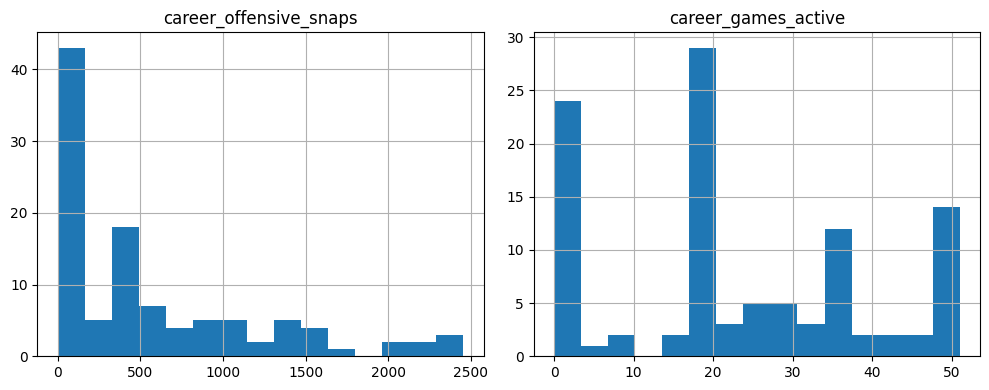

In [47]:
wr_success[
    ["career_offensive_snaps", "career_games_active"]
].hist(figsize=(10, 4), bins=15)


plt.tight_layout()
plt.show()

* The distribution of career offensive snaps is right-skewed. Most wide receivers have relatively lower career snap counts, while a smaller       
  number have much higher snap counts, creating a long tail toward the right.

* The career games active distribution shows several concentrations of players at different career totals. Some players have very few active   
  games, while others have played in many more.

**Defining the Initial Subgroup: Wide Receivers and the 40-Yard Dash**

`Question:` Which subgroup and drill provide a practical starting point for exploring Combine tracking data?

`Why:` Wide receivers form a sufficiently large subgroup in the available records, and the 40-yard dash provides a useful sprint sequence to examine. This is an exploratory choice—not a claim that WRs or the 40-yard dash are the best predictors of NFL success. We may revisit the scope as the analysis develops.

In [48]:
# Filter the combine dataset of players 

wr_combine = combine[combine["combine_position"] == "WR"].copy()

wr_combine.shape

(107, 18)

### **investigate 40 yard dash column**

In [49]:
wr_combine["forty"].describe()

count    97.000000
mean      4.472165
std       0.088544
min       4.300000
25%       4.400000
50%       4.460000
75%       4.540000
max       4.700000
Name: forty, dtype: float64

In [50]:
wr_combine["forty"].isnull().sum()

np.int64(10)

In [51]:
wr_combine["forty"].info()

<class 'pandas.Series'>
Index: 107 entries, 3 to 447
Series name: forty
Non-Null Count  Dtype  
--------------  -----  
97 non-null     float64
dtypes: float64(1)
memory usage: 1.7 KB


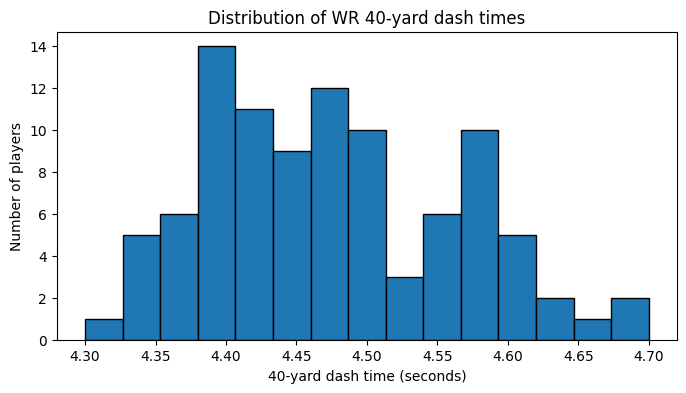

In [52]:
plt.figure(figsize=(8, 4))

plt.hist(wr_combine["forty"].dropna(), bins=15, edgecolor="black")

plt.xlabel("40-yard dash time (seconds)")
plt.ylabel("Number of players")
plt.title("Distribution of WR 40-yard dash times")

plt.show()

In [53]:
wr_combine["forty"].skew()

np.float64(0.4458172117026798)

- The `WR 40-yard dash` distribution shows mild positive skewness `(0.446)`. Although the histogram does not display a pronounced right-skewed shape, the distribution has a somewhat longer tail toward higher times.

  **Because** : 
  > Left side: The times extend down to approximately 4.30.

  > Right side: The times extend up to approximately 4.70.

  * The right tail extends farther than the left tail. That is one indication of positive skewness.

**Matching Wide Receivers Across Datasets**

`Question:` How many WR records can be matched between the Combine and career-success datasets using nfl_id?

`Why:` Dataset joins must be verified so that player measurements are paired with the correct career outcomes.

In [54]:
wr_combine["nfl_id"].isin(wr_success["nfl_id"]).value_counts()

nfl_id
True     106
False      1
Name: count, dtype: int64

`True` = 106: 106 players from wr_combine have matching nfl_id values in wr_success.

`False` = 1: One player from wr_combine does not have a matching ID in wr_success.

### **Identify the unmatched id**

In [55]:
wr_combine.loc[
    ~wr_combine["nfl_id"].isin(wr_success["nfl_id"]),
    ["nfl_id", "draft_year", "combine_position", "forty"]
]

,nfl_id,draft_year,combine_position,forty
111,56062,2023,WR,4.54


**Check the original success DataFrame for this id**

In [56]:
success[success["nfl_id"] == 56062]

,nfl_id,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started,ap_all_pro_1st_team,ap_all_pro_2nd_team,pro_bowl_original_ballot
93,56062,1077,0,551,51,18,0,0,0


**We will find player's recorded position in the original players dataset.**

In [57]:
players[players["nfl_id"] == 56062]

,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
93,56062,Elijah Higgins,2023,TE,2000-10-27,Stanford,Pacific Twelve Conference,6.0,20.0,197.0


### **Comparing the positions across the two datasets, to see differences**

**Comparing Combine Position and NFL Position**

`Question:` How often do Combine and NFL position labels differ, and what might those differences represent?

`Why:` Position labels can reflect different classification systems. Differences should be inspected rather than automatically treated as errors.

In [58]:
position_check = combine.merge(
    players[["nfl_id", "nfl_position"]],
    on="nfl_id",
    how="inner"
)

position_check[
    position_check["combine_position"] != position_check["nfl_position"]
][["nfl_id", "combine_position", "nfl_position"]]

,nfl_id,combine_position,nfl_position
1,56010,DB,SS
9,56020,DB,CB
13,55914,DL,DT
14,56514,DL,NT
16,56581,DL,DT
...,...,...,...
505,58259,OL,T
506,58454,OL,G
507,58261,OL,T
508,58896,OL,T


**We have found 358 players out of 510 whose Combine position differs from their recorded NFL position.**

### **Investigate Relationship between these positions**

In [59]:
pd.crosstab(
    position_check["combine_position"],
    position_check["nfl_position"]
)

nfl_position,C,CB,DB,DE,DT,FB,FS,G,ILB,MLB,NT,OLB,RB,SS,T,TE,WR
combine_position,,,,,,,,,,,,,,,,,
DB,0,60,5,0,0,0,25,0,2,1,0,0,1,28,0,0,0
DL,0,0,0,36,47,0,0,0,0,0,5,30,0,0,0,0,0
OL,20,0,0,0,0,0,0,51,0,0,0,0,0,0,50,0,0
TE,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,41,0
WR,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,106


- `Combine position:` The broader position group under which a player participated in the Combine.

- `NFL position:` The more specific position recorded for that player in the NFL player dataset.

- For example, A player participating in the Combine as a defensive back might eventually be listed as a cornerback (CB), free safety (FS), or strong safety (SS).

**The cross-tabulation revealed differences between Combine position groups and NFL position labels. These differences appear to reflect broader Combine classifications compared with more specific NFL position labels. Therefore, position mismatches should not automatically be treated as errors. Position consistency must be considered when matching and analysing players.**

### **Creating the Wide-Receiver Analysis Dataset**

`Question:` Can traditional Combine measurements and career-success records be combined into one WR analysis table?

`Why:` A single joined table makes it possible to inspect the availability of candidate predictors and outcomes together. We create a new table and preserve the source tables.

**Merge the two datasets**

We currently have:

- `wr_combine:` 107 WR records, including their 40-yard dash times.

- `wr_success:` 106 WR records, including their career-performance statistics.

- We use a new variable, `wr_analysis`, so our original datasets remain unchanged.

In [60]:
wr_analysis = wr_combine.merge(
    wr_success,
    on="nfl_id",
    how="inner",
    validate="one_to_one"
)

In [61]:
wr_analysis.shape

(106, 27)

In [62]:
wr_analysis.columns

Index(['draft_year', 'nfl_id', 'combine_position', 'combine_height',
       'combine_weight', 'hand_size', 'arm_length', 'wing_span',
       'ten_yd_split', 'forty', 'vertical', 'broad_jump', 'three_cone',
       'short_shuttle', 'bench_reps', 'ngs_athleticism_score',
       'ngs_college_production_score', 'ngs_final_score',
       'career_offensive_snaps', 'career_defensive_snaps',
       'career_special_teams_snaps', 'career_games_active',
       'career_games_started', 'ap_all_pro_1st_team', 'ap_all_pro_2nd_team',
       'pro_bowl_original_ballot', 'nfl_position'],
      dtype='str')

In [63]:
wr_analysis.info()

<class 'pandas.DataFrame'>
RangeIndex: 106 entries, 0 to 105
Data columns (total 27 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   draft_year                    106 non-null    int64  
 1   nfl_id                        106 non-null    int64  
 2   combine_position              106 non-null    str    
 3   combine_height                106 non-null    float64
 4   combine_weight                106 non-null    int64  
 5   hand_size                     106 non-null    float64
 6   arm_length                    106 non-null    float64
 7   wing_span                     106 non-null    float64
 8   ten_yd_split                  96 non-null     float64
 9   forty                         96 non-null     float64
 10  vertical                      95 non-null     float64
 11  broad_jump                    94 non-null     float64
 12  three_cone                    32 non-null     float64
 13  short_shuttle   

### **Calculate missing percentages in our final dataset**

(we investigated missing values in the original Combine dataset of 510 players. Now we are examining missingness in our actual research sample of `106 WR players`.)

**Missing Measurements in the Actual WR Analysis Sample**

`Question:` Which traditional measurements are missing in the joined WR sample?

`Why:` Dataset-wide missingness may not reflect the subgroup we actually analyze, so we check the sample directly

In [64]:
combine_features = [ "ten_yd_split", "forty", "vertical", "broad_jump", "three_cone", "short_shuttle", "bench_reps"]

missing_summary = pd.DataFrame({
    "missing_count": wr_analysis[combine_features].isnull().sum(),
    "missing_percentage": (
        wr_analysis[combine_features].isnull().mean() * 100
    ).round(2)
})

missing_summary

,missing_count,missing_percentage
ten_yd_split,10,9.43
forty,10,9.43
vertical,11,10.38
broad_jump,12,11.32
three_cone,74,69.81
short_shuttle,68,64.15
bench_reps,78,73.58


In [65]:
wr_analysis[["ten_yd_split", "forty"]].corr()

,ten_yd_split,forty
ten_yd_split,1.000000,0.381744
forty,0.381744,1.000000


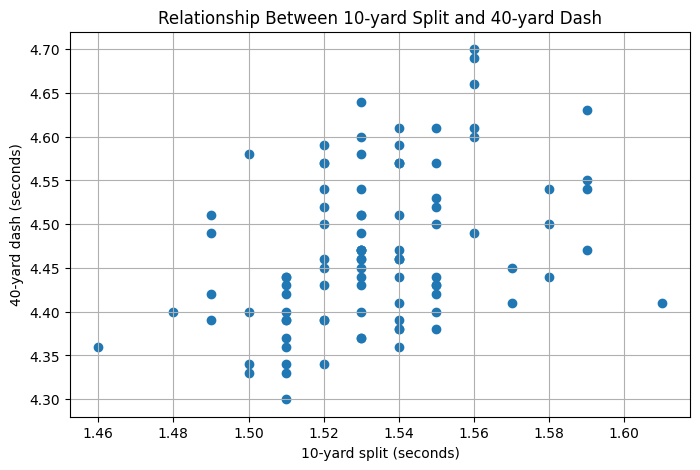

In [66]:
plt.figure(figsize=(8, 5))

plt.scatter(
    wr_analysis["ten_yd_split"],
    wr_analysis["forty"]
)

plt.xlabel("10-yard split (seconds)")
plt.ylabel("40-yard dash (seconds)")
plt.title("Relationship Between 10-yard Split and 40-yard Dash")

plt.grid(True)
plt.show()

1. The correlation between `10-yard` split and `40-yard` dash is `+0.382`.

2. Both measurements have a positive relationship, but it is not particularly strong.

3. The scatter plot shows individual player observations.

4. Several players have similar 10-yard split times but different 40-yard dash times.

5. This motivates further investigation into differences in sprint performance beyond the first 10 yards.

**Investigating Early Sprint Performance and the Full 40-Yard Dash**

`Question:` How does the first 10 yards relate to the remaining 30 yards of a player's sprint?

`Why:` The full 40-yard time summarizes the entire sprint. Separating the first 10 yards from the remaining distance lets us explore early acceleration and later sprint performance as distinct descriptive components.We define the remaining 30-yard time as the full 40-yard time minus the 10-yard split.

In [67]:
wr_analysis["remaining_30yd_time"] = (
    wr_analysis["forty"] - wr_analysis["ten_yd_split"]
)

In [68]:
wr_analysis[
    ["ten_yd_split", "forty", "remaining_30yd_time"]
].head()

,ten_yd_split,forty,remaining_30yd_time
0,1.51,4.33,2.82
1,1.52,4.54,3.02
2,NaN,NaN,NaN
3,1.49,4.51,3.02
4,1.55,4.57,3.02


In [69]:
# This will give us missing values in all 3 10-40-30

wr_analysis[
    ["ten_yd_split", "forty", "remaining_30yd_time"]
].isnull().sum()

ten_yd_split           10
forty                  10
remaining_30yd_time    10
dtype: int64

In [70]:
# we will retain the records of the missing values from original data set

wr_analysis[
    wr_analysis["remaining_30yd_time"].isnull()
][["nfl_id", "ten_yd_split", "forty", "remaining_30yd_time"]]

,nfl_id,ten_yd_split,forty,remaining_30yd_time
2,55885,NaN,NaN,NaN
15,55884,NaN,NaN,NaN
26,56042,NaN,NaN,NaN
33,56471,NaN,NaN,NaN
51,57824,NaN,NaN,NaN
54,57361,NaN,NaN,NaN
81,58717,NaN,NaN,NaN
83,58751,NaN,NaN,NaN
84,58263,NaN,NaN,NaN
105,58968,NaN,NaN,NaN


**Investigating Missing Sprint Measurements**

`Question:` Which WRs lack the sprint measurements required for this analysis, and are they concentrated in particular draft years?

`Why:` We should describe missingness before excluding any records from a specific calculation

1. 10 out of 106 WR players have no recorded values for these two sprint measurements in our current dataset.

2. We have retained their records rather than deleting them.

3. We do not yet know why their measurements are missing.

In [71]:
# Let's check whether these 10 players belong to particular draft years.

missing_players = wr_analysis[
    wr_analysis["remaining_30yd_time"].isnull()
]

missing_players["draft_year"].value_counts().sort_index()

draft_year
2023    4
2024    2
2025    4
Name: count, dtype: int64

In [72]:
# Compare missing values with total players per year

pd.crosstab(
    wr_analysis["draft_year"],
    wr_analysis["remaining_30yd_time"].isnull(),
    margins=True
)

remaining_30yd_time,False,True,All
draft_year,,,
2023,34,4,38
2024,29,2,31
2025,33,4,37
All,96,10,106


In [73]:
# Calculate missing percentage 

missing_by_year = pd.crosstab(
    wr_analysis["draft_year"],
    wr_analysis["remaining_30yd_time"].isnull(),
    normalize="index"
) * 100

missing_by_year.round(2)

remaining_30yd_time,False,True
draft_year,,
2023,89.47,10.53
2024,93.55,6.45
2025,89.19,10.81


### **Missing Sprint Measurements Across Draft Years**

We identified 10 WR players with missing 10-yard split and 40-yard dash measurements.

The missing records are distributed across three draft years:

| Draft year | Total players | Missing players | Missing percentage |
|---|---:|---:|---:|
| 2023 | 38 | 4 | 10.53% |
| 2024 | 31 | 2 | 6.45% |
| 2025 | 37 | 4 | 10.81% |

Although `2023` and `2025` have the same number of missing records, their missing percentages differ because their total player counts are different.

**Conclusion:** Missing measurements are present across all three draft years. Further investigation is required to understand the reasons behind the missing data.

**Defining the Valid Sprint-Time Sample**

`Question:` How many WRs have the measurements needed to calculate remaining-30-yard time, and how are they distributed by draft year?

`Why:` The calculation requires both the 10-yard split and the full 40-yard time, so this subset must be explicitly defined

In [74]:
# Check valid players by draft years

valid_players = wr_analysis[
    wr_analysis["remaining_30yd_time"].notnull()
]

valid_players["draft_year"].value_counts().sort_index()

draft_year
2023    34
2024    29
2025    33
Name: count, dtype: int64

In [75]:
# Examine the distribution of remaining 30-yard times

valid_players["remaining_30yd_time"].describe()

count    96.000000
mean      2.937813
std       0.082375
min       2.790000
25%       2.877500
50%       2.930000
75%       3.000000
max       3.140000
Name: remaining_30yd_time, dtype: float64

In [76]:
# Compare the remaining 30-yard times across draft years. 
# This will help us see whether combining all three years is hiding any year-to-year differences.


valid_players.groupby("draft_year")["remaining_30yd_time"].describe()

,count,mean,std,min,25%,50%,75%,max
draft_year,,,,,,,,
2023,34.0,2.965588,0.082836,2.82,2.91,2.94,3.02,3.13
2024,29.0,2.911724,0.070004,2.80,2.87,2.91,2.94,3.07
2025,33.0,2.932121,0.085504,2.79,2.86,2.92,2.98,3.14


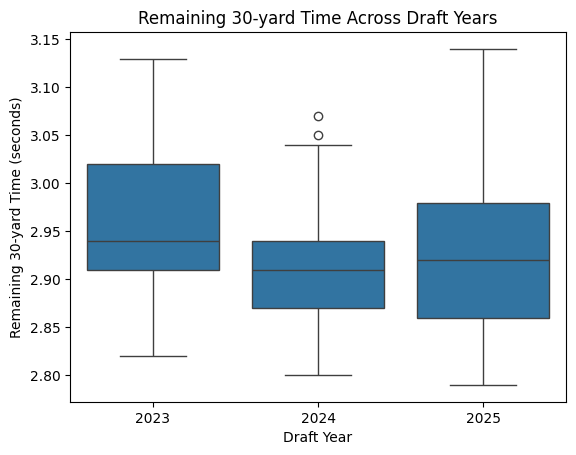

In [77]:
# Let's visualise the comparison
# A box plot will help us compare the median, spread and potential outliers across the three years.


sns.boxplot(
    data=valid_players,
    x="draft_year",
    y="remaining_30yd_time"
)

plt.title("Remaining 30-yard Time Across Draft Years")
plt.xlabel("Draft Year")
plt.ylabel("Remaining 30-yard Time (seconds)")
plt.show()

`**2023**`

- Median: 2.94 seconds.

- The middle 50% of players fall approximately between 2.91 and 3.02 seconds.

- Its median is the highest of the three groups.

`**2024**`

- Median: 2.91 seconds.

- The middle 50% fall approximately between 2.87 and 2.94 seconds.

- Two potential outliers appear around 3.05 and 3.07 seconds.

`**2025**`

- Median: 2.92 seconds.

- The middle 50% fall approximately between 2.86 and 2.98 seconds.

- Its median is between the 2023 and 2024 medians.

- The box plot shows relatively similar distributions of remaining `30-yard` times across the 2023, 2024 and 2025 WR groups.

- The `2024` group has the lowest median time `(2.91 seconds)`, followed by `2025 (2.92 seconds)` and `2023 (2.94 seconds)`. 

- Two potential outliers are observed in 2024. 

- Although there are small differences between the groups, their distributions overlap, so we cannot conclude that one draft-year group is definitively faster than another.

- We use the median to compare typical player performance because lower remaining `30-yard` times indicate faster performance. 

- The median is particularly useful when outliers are present because extreme observations have little influence on it compared with the mean.

**Examining Individual Sprint Measurements**

`Question:` Do individual 10-yard split values show a linear association with remaining-30-yard time?

`Why:` A scatter plot and correlation can summarize the relationship, but correlation alone does not establish predictive usefulness or causation

In [78]:
# Compare individual player performances

valid_players[
    ["nfl_id", "draft_year", "ten_yd_split", "forty", "remaining_30yd_time"]
].sort_values("ten_yd_split").head(10)

,nfl_id,draft_year,ten_yd_split,forty,remaining_30yd_time
29,55990,2023,1.46,4.36,2.90
18,55965,2023,1.48,4.40,2.92
3,55920,2023,1.49,4.51,3.02
27,55934,2023,1.49,4.49,3.00
39,57263,2024,1.49,4.39,2.90
82,58338,2025,1.49,4.42,2.93
63,57144,2024,1.50,4.33,2.83
14,55938,2023,1.50,4.40,2.90
86,58333,2025,1.50,4.34,2.84
10,55959,2023,1.50,4.58,3.08


In [79]:
# Do players who complete the first 10 yards faster also tend to complete the remaining 30 yards faster?

valid_players[["ten_yd_split", "remaining_30yd_time"]].corr()

,ten_yd_split,remaining_30yd_time
ten_yd_split,1.000000,0.093611
remaining_30yd_time,0.093611,1.000000


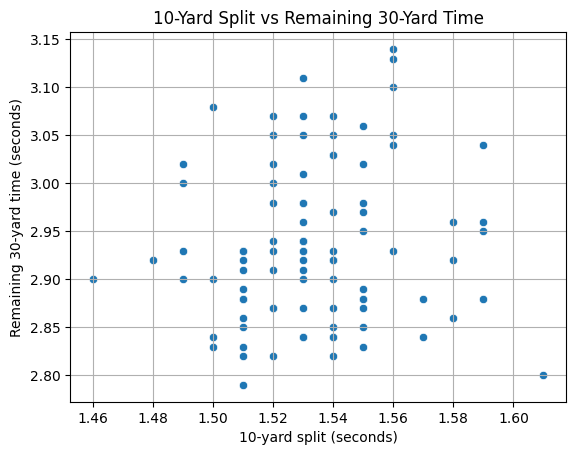

In [80]:

sns.scatterplot(
    data=valid_players,
    x="ten_yd_split",
    y="remaining_30yd_time"
)

plt.title("10-Yard Split vs Remaining 30-Yard Time")
plt.xlabel("10-yard split (seconds)")
plt.ylabel("Remaining 30-yard time (seconds)")
plt.grid(True)
plt.show()

Among `96 wide receivers` with valid measurements, the 10-yard split showed a very weak positive linear correlation with the remaining 30-yard time `(r = 0.094)`. 

This suggests little linear association between early sprint time and performance over the remaining 30 yards in this sample.

## **Combine Tracking Data (Investigation)**

**Combine Tracking Dataset — Initial Exploration**

`Question:` What tracking variables, drill types, and record structure are available in the tracking dataset?

`Why:` We need to understand the scale and contents of the tracking data before filtering it to a specific drill

In [81]:
c_tracking = pd.read_csv(data_dir / "combine_tracking.csv")

In [82]:
c_tracking.head()

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
0,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.200,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.785924,28.285528,0.220828,0.682443,0.011085,250.278576
1,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.300,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.723780,28.297391,0.332931,0.619551,0.003864,257.319206
2,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.400,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.632680,28.279528,0.481838,0.596455,0.008305,253.176813
3,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.500,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.544022,28.243767,0.599350,0.664436,0.007964,247.044153
4,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02T18:56:38.600,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.471466,28.210294,0.657540,0.908250,0.005382,240.622668


In [83]:
c_tracking.shape

(463189, 14)

In [84]:
c_tracking.info()

<class 'pandas.DataFrame'>
RangeIndex: 463189 entries, 0 to 463188
Data columns (total 14 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   draft_year   463189 non-null  int64  
 1   event_id     463189 non-null  str    
 2   nfl_id       463189 non-null  int64  
 3   entity_type  463189 non-null  str    
 4   time         463189 non-null  str    
 5   drill_type   463189 non-null  str    
 6   drill_name   463189 non-null  str    
 7   attempt      463189 non-null  int64  
 8   x            463189 non-null  float64
 9   y            463189 non-null  float64
 10  s            463189 non-null  float64
 11  a            463189 non-null  float64
 12  dis          463189 non-null  float64
 13  dir          463189 non-null  float64
dtypes: float64(6), int64(3), str(5)
memory usage: 49.5 MB


In [85]:
c_tracking.describe()

,draft_year,nfl_id,attempt,x,y,s,a,dis,dir
count,463189.000000,463189.000000,463189.000000,463189.000000,463189.000000,463189.000000,463189.000000,463189.000000,463189.000000
mean,2024.093223,57415.578740,3.049224,44.262522,24.039636,5.130768,2.813108,0.352934,149.667876
std,0.819870,999.428392,3.325315,17.337613,14.253090,3.480071,1.940565,0.587834,96.420756
min,2023.000000,55867.000000,1.000000,1.300000,-11.459799,0.000000,0.000000,0.000000,0.000000
25%,2023.000000,56408.000000,1.000000,34.766667,14.900000,2.412828,1.246800,0.054444,88.076853
50%,2024.000000,57331.000000,1.000000,44.500000,26.085594,4.920000,2.498853,0.217781,112.121869
75%,2025.000000,58336.000000,4.000000,48.221888,30.400000,7.343333,4.089669,0.490020,234.173429
max,2025.000000,59278.000000,17.000000,103.900000,66.282837,25.794156,44.607283,45.285317,359.999689


In [86]:
c_tracking["drill_type"].value_counts()

drill_type
SKILL_DRILLS_WR     120383
SKILL_DRILLS_DB      94623
SKILL_DRILLS_DL      77428
SKILL_DRILLS_OL      61129
FORTY_YARD_DASH      41500
SKILL_DRILLS_TE      37222
THREE_CONE_DRILL     15951
SHORT_SHUTTLE        11690
SKILL_DRILLS_LB       3263
Name: count, dtype: int64

In [87]:
c_tracking["drill_name"].nunique()

56

**Selecting the 40-Yard-Dash Tracking Records**

`Question:` How many tracking observations belong to the 40-yard dash drill?

`Why:` Filtering to the target drill gives us a manageable and relevant dataset for the initial movement analysis

In [88]:
# Investigate the 40-yard dash

forty_data = c_tracking[
    c_tracking["drill_type"] == "FORTY_YARD_DASH"
]

forty_data["drill_name"].value_counts()

drill_name
FORTY_YARD_DASH    41500
Name: count, dtype: int64

**There are `41,500` tracking observations belonging to the `FORTY_YARD_DASH` drill.**

In [89]:
forty_data.shape

(41500, 14)

**Understanding Events, Players, and Attempts**

`Question:` How many unique event IDs, players, and attempts are present in the 40-yard-dash records?

`Why:` These are different units. An observation is a timestamped row, an event is a recorded attempt, and a player may have multiple events

In [90]:
# How many unique events

forty_data["event_id"].nunique()

793

In [91]:
# How many unique players

forty_data["nfl_id"].nunique()

418

In [92]:
#  How many attempts

forty_data["attempt"].nunique()

4

In [93]:
# How many observations belong to each attempt number 

forty_data["attempt"].value_counts().sort_index()

attempt
1    19495
2    18144
3     3154
4      707
Name: count, dtype: int64

In [94]:
# How many distinct event IDs exist for each attempt number?

forty_data.groupby("attempt")["event_id"].nunique()

attempt
1    372
2    347
3     61
4     13
Name: event_id, dtype: int64

In [95]:
# Inspect some event IDs and their associated players and attempts.

forty_data[
    ["event_id", "nfl_id", "draft_year", "attempt", "time"]
].head(15)

,event_id,nfl_id,draft_year,attempt,time
588,20250302101000_1740946089384_000,58896,2025,1,2025-03-02T20:08:02.500
589,20250302101000_1740946089384_000,58896,2025,1,2025-03-02T20:08:02.600
590,20250302101000_1740946089384_000,58896,2025,1,2025-03-02T20:08:02.700
591,20250302101000_1740946089384_000,58896,2025,1,2025-03-02T20:08:02.800
592,20250302101000_1740946089384_000,58896,2025,1,2025-03-02T20:08:02.900
593,20250302101000_1740946089384_000,58896,2025,1,2025-03-02T20:08:03.000
594,20250302101000_1740946089384_000,58896,2025,1,2025-03-02T20:08:03.100
595,20250302101000_1740946089384_000,58896,2025,1,2025-03-02T20:08:03.200
596,20250302101000_1740946089384_000,58896,2025,1,2025-03-02T20:08:03.300
597,20250302101000_1740946089384_000,58896,2025,1,2025-03-02T20:08:03.400


**Validating Event IDs**

`Question:` Does each event ID identify exactly one player and one attempt?

`Why:` Before grouping or feature engineering, we must verify that event IDs consistently represent individual recorded attempts

In [96]:
# verify whether each event ID belongs to exactly one player and one attempt.

event_check = forty_data.groupby("event_id").agg(
    unique_players=("nfl_id", "nunique"),
    unique_attempts=("attempt", "nunique"),
    observations=("event_id", "size")
)

event_check[["unique_players", "unique_attempts"]].value_counts()

unique_players  unique_attempts
1               1                  793
Name: count, dtype: int64

In [97]:
event_check["observations"].describe()

count    793.000000
mean      52.332913
std        3.592942
min       45.000000
25%       50.000000
50%       51.000000
75%       55.000000
max       90.000000
Name: observations, dtype: float64

**Selecting Wide-Receiver Tracking Records**

`Question:` How many WRs from our analysis sample appear in the 40-yard-dash tracking data, and how many events are available for them?

`Why:` This establishes the tracking coverage for the subgroup and identifies any players or events that are not represented

In [98]:
# Isolate wide receivers(we will find how many of 106 appear in the 40-yard dash tracking dataset.)

wr_ids = wr_analysis["nfl_id"].unique()

wr_forty_data = forty_data[
    forty_data["nfl_id"].isin(wr_ids)
].copy()

print("Tracking observations:", len(wr_forty_data))
print("Unique WRs:", wr_forty_data["nfl_id"].nunique())
print("Unique events:", wr_forty_data["event_id"].nunique())

Tracking observations: 8772
Unique WRs: 93
Unique events: 174


In [99]:
# How many events does each WR have?

events_per_wr = wr_forty_data.groupby("nfl_id")["event_id"].nunique()

events_per_wr.value_counts().sort_index()

event_id
1    12
2    81
Name: count, dtype: int64

**Most of our `wide receivers` (81 out of 93) have two recorded `40-yard` dash events, while 12 have only one.**

**We now need to establish whether those two events correspond to `attempt 1` and `attempt 2` for each player.**

In [100]:
# Inspect the attempt distribution(create a table containing one row per player-event combination:)

wr_events = wr_forty_data[
    ["nfl_id", "event_id", "attempt"]
].drop_duplicates()

wr_events.sort_values(
    ["nfl_id", "attempt"]
).head(15)

,nfl_id,event_id,attempt
427022,55887,6414e5fde3d8e72dcdc8d181-2023,1
426972,55887,6414e5fde3d8e72dcdc8d1c0-2023,3
367234,55904,6414e684e3d8e72dcdcb4d2a-2023,1
366401,55904,6414e684e3d8e72dcdcb4d52-2023,2
445329,55915,6414e684e3d8e72dcdcb4d33-2023,1
444541,55915,6414e684e3d8e72dcdcb4d5f-2023,2
456359,55920,6414e684e3d8e72dcdcb4d36-2023,1
456407,55920,6414e684e3d8e72dcdcb4d62-2023,2
446071,55928,6414e684e3d8e72dcdcb4d28-2023,1
378591,55934,6414e5fde3d8e72dcdc8d194-2023,1


In [101]:
wr_events["attempt"].value_counts().sort_index()

attempt
1    87
2    72
3    12
4     3
Name: count, dtype: int64

**Not every wide receiver has the same number of 40-yard dash attempts.**



**Individual Player Case Study — `Player 55904`**

`Question:` What can we learn by examining one player's recorded 40-yard-dash attempts across speed, acceleration, coordinates, direction, and dis?

`Why:` A case study helps us understand the meaning and behavior of the variables before extending the investigation across the full sample. It is not intended to represent all WRs### Investigating one player 

### **Investigating one player**

In [102]:


wr_events.groupby("nfl_id").agg(
    total_events=("event_id", "nunique"),
    attempts=("attempt", lambda x: sorted(x.unique()))
).head(15)

,total_events,attempts
nfl_id,,
55887,2,"[1, 3]"
55904,2,"[1, 2]"
55915,2,"[1, 2]"
55920,2,"[1, 2]"
55928,1,[1]
55934,1,[1]
55938,2,"[1, 2]"
55939,2,"[2, 4]"
55959,2,"[1, 2]"


In [103]:


# Extract this player's tracking data.

sample_player_id = 55904

player_data = wr_forty_data[
    wr_forty_data["nfl_id"] == sample_player_id
].copy()

In [104]:
# Check their events and observations.

player_data.groupby(["event_id", "attempt"]).agg(
    observations=("time", "count"),
    start_time=("time", "min"),
    end_time=("time", "max")
)

,,observations,start_time,end_time
event_id,attempt,,,
6414e684e3d8e72dcdcb4d2a-2023,1,48,2023-03-04T21:24:09.000,2023-03-04T21:24:13.700
6414e684e3d8e72dcdcb4d52-2023,2,48,2023-03-04T21:38:39.300,2023-03-04T21:38:44.000


In [105]:
# Inspect the actual movement records.

player_data[
    ["event_id", "attempt", "time", "x", "y", "s", "a", "dis", "dir"]
].head(10)

,event_id,attempt,time,x,y,s,a,dis,dir
366401,6414e684e3d8e72dcdcb4d52-2023,2,2023-03-04T21:38:39.300,11.100000,-0.600000,0.670000,3.704683,0.001111,80.584374
366402,6414e684e3d8e72dcdcb4d52-2023,2,2023-03-04T21:38:39.400,11.200000,-0.566667,1.090000,4.264839,0.010062,85.440050
366403,6414e684e3d8e72dcdcb4d52-2023,2,2023-03-04T21:38:39.500,11.333333,-0.566667,1.646667,5.817526,0.017778,87.797402
366404,6414e684e3d8e72dcdcb4d52-2023,2,2023-03-04T21:38:39.600,11.533333,-0.566667,2.286667,6.343720,0.040000,88.663898
366405,6414e684e3d8e72dcdcb4d52-2023,2,2023-03-04T21:38:39.700,11.800000,-0.566667,2.980000,6.693363,0.071111,88.398186
366406,6414e684e3d8e72dcdcb4d52-2023,2,2023-03-04T21:38:39.800,12.166667,-0.533333,3.666667,6.773354,0.134449,88.802172
366407,6414e684e3d8e72dcdcb4d52-2023,2,2023-03-04T21:38:39.900,12.566667,-0.533333,4.370000,6.633347,0.160000,88.951224
366408,6414e684e3d8e72dcdcb4d52-2023,2,2023-03-04T21:38:40.000,13.033333,-0.533333,5.030000,6.320022,0.217778,89.354120
366409,6414e684e3d8e72dcdcb4d52-2023,2,2023-03-04T21:38:40.100,13.566667,-0.533333,5.670000,5.860004,0.284444,89.326359
366410,6414e684e3d8e72dcdcb4d52-2023,2,2023-03-04T21:38:40.200,14.166667,-0.533333,6.230000,5.410037,0.360000,89.540172


- Speed increases initially, but the last observation shows it has started decreasing.

- Acceleration also increases initially, reaches a peak in the displayed rows, and then decreases.

- Direction changes; it doesn't necessarily have to increase continuously.

- Distance changes between observations.

Also, these are only the first `10 out of 48` observations. We cannot describe the entire sprint from these rows alone.

**Comparing the Player's Recorded Attempts**

`Question:` Do the two attempts show similar summary values for speed and acceleration?

`Why:` Summary statistics provide a first comparison, while the time-series plots show how the movement profiles unfold

In [106]:
# comparing both attempts using their speed and acceleration statistics.

player_data.groupby("attempt").agg(
    mean_speed=("s", "mean"),
    max_speed=("s", "max"),
    mean_acceleration=("a", "mean"),
    max_acceleration=("a", "max"),
    total_observations=("time", "count")
)

,mean_speed,max_speed,mean_acceleration,max_acceleration,total_observations
attempt,,,,,
1,8.523264,11.286667,2.228947,6.301143,48
2,8.630139,11.326667,2.202305,6.773354,48


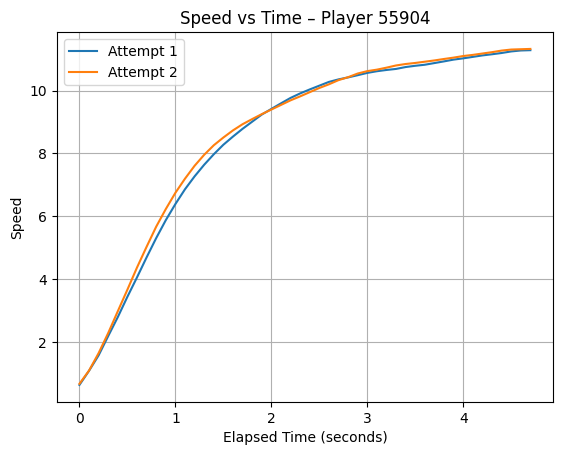

In [107]:
# We'll plot both attempts on the same graph.


# Convert time into datetime format
player_data["time"] = pd.to_datetime(player_data["time"])

# Sort observations chronologically within each attempt
player_data = player_data.sort_values(["attempt", "time"])

# Calculate elapsed time from the beginning of each attempt
player_data["elapsed_time"] = (
    player_data["time"] -
    player_data.groupby("attempt")["time"].transform("min")
).dt.total_seconds()

# Plot speed against elapsed time
for attempt, data in player_data.groupby("attempt"):
    plt.plot(
        data["elapsed_time"],
        data["s"],
        label=f"Attempt {attempt}"
    )

plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Speed")
plt.title("Speed vs Time – Player 55904")
plt.legend()
plt.grid(True)
plt.show()

- Both attempts contain 48 observations.

- Both attempts last approximately 4.7 seconds.

- Attempt 2 has a slightly higher mean speed.

- Attempt 2 has a slightly higher maximum speed.

- Attempt 1 has a slightly higher mean acceleration.

- Their speed profiles are quite similar.

**These are preliminary observations about one player's two attempts, not conclusions about all wide receivers.**

**Comparing Acceleration Profiles Across Attempts**

`Question:` How does acceleration change over time in each attempt?

`Why:` The time series can show when acceleration rises, peaks, and declines—information hidden by a single summary value

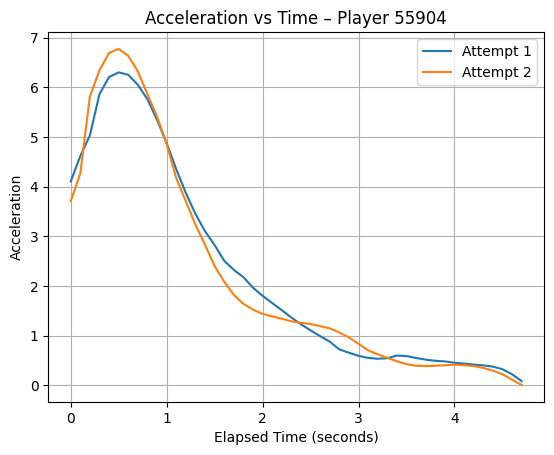

In [108]:
# investigating acceleration against elapsed time, using exactly the same approach.
# We want to understand when acceleration is high, when it decreases, and whether the two attempts have different acceleration patterns.

for attempt, data in player_data.groupby("attempt"):
    plt.plot(
        data["elapsed_time"],
        data["a"],
        label=f"Attempt {attempt}"
    )

plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Acceleration")
plt.title("Acceleration vs Time – Player 55904")
plt.legend()
plt.grid(True)
plt.show()

**Acceleration graph interpretation**

`Attempt 1 (blue):`

- Acceleration starts at approximately 4.1.

- It increases and reaches a peak of approximately 6.3 around 0.5 seconds.

- After that, acceleration gradually decreases.

- Towards the end, it approaches zero.

`Attempt 2 (orange):`

- Acceleration starts at approximately 3.7.

- It increases more rapidly and reaches a higher peak of approximately 6.8.

- After reaching its peak, it decreases.

- Its acceleration is slightly lower than Attempt 1 during some later portions.

- Towards the end, it also approaches zero.

**Comparing X-Y Movement Trajectories**

`Question:` Do the two attempts follow similar paths in the recorded coordinate plane?

`Why:` Comparing paths provides a visual check of movement direction and trajectory, while keeping the axes at equal scale avoids distortion

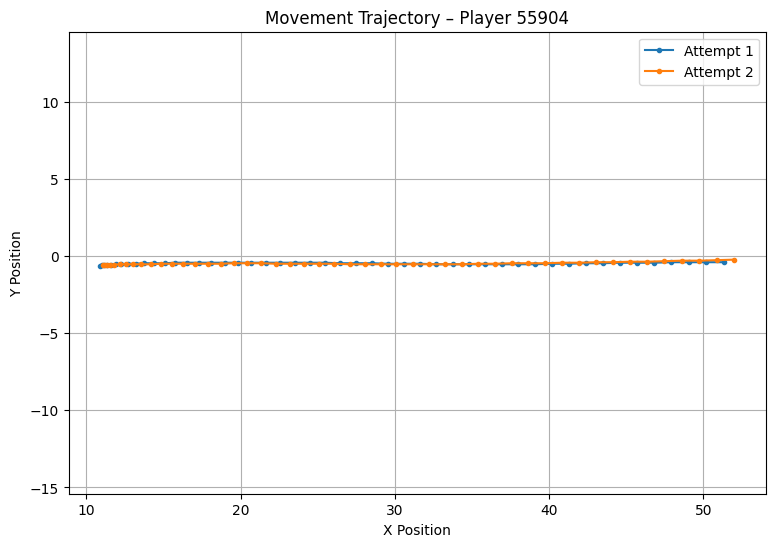

In [109]:
# Plot the player's movement path (X vs Y)

plt.figure(figsize=(9, 6))

for attempt, data in player_data.groupby("attempt"):
    plt.plot(
        data["x"],
        data["y"],
        marker="o",
        markersize=3,
        label=f"Attempt {attempt}"
    )

plt.xlabel("X Position")
plt.ylabel("Y Position")
plt.title("Movement Trajectory – Player 55904")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

- The player follows a relatively straight path in both attempts.

- The two trajectories are very similar.

- There are small differences in the recorded positions.

- There are no obvious large changes in the movement direction.

**Investigating the Direction Variable**

`Question:` How does recorded direction change during each attempt?

`Why:` Direction describes orientation/heading and should not be interpreted as speed or acceleration

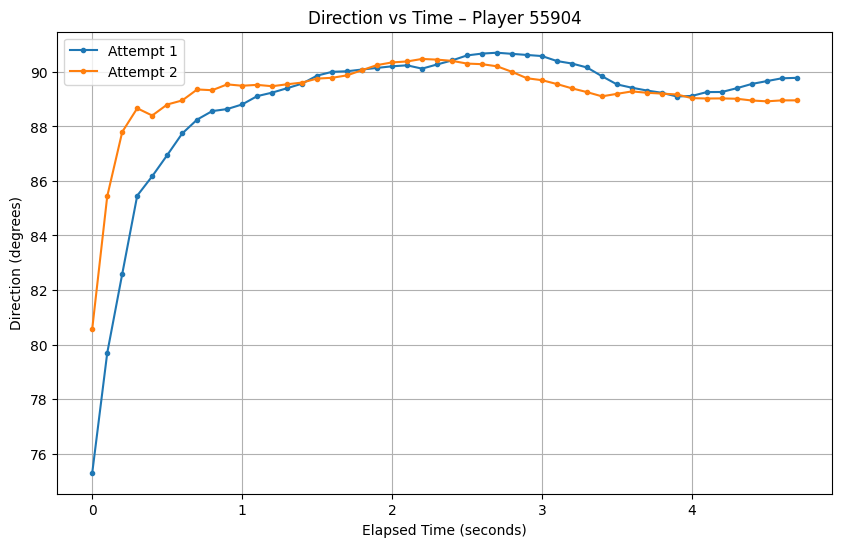

In [110]:
# Investigate the dir (direction) variable.

plt.figure(figsize=(10, 6))

for attempt, data in player_data.groupby("attempt"):

    data = data.sort_values("time")

    plt.plot(
        data["elapsed_time"],
        data["dir"],
        marker="o",
        markersize=3,
        label=f"Attempt {attempt}"
    )

plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Direction (degrees)")
plt.title("Direction vs Time – Player 55904")
plt.legend()
plt.grid(True)
plt.show()

- `Beginning:` Both attempts show a considerable change in direction. Attempt 2 changes more quickly initially.

- `Around 1.5–2.5 seconds:` Both attempts approach approximately 90–91°.

- `Later:` Direction changes slightly, with both attempts showing small fluctuations.

- `Between attempts:` There are differences, particularly during the initial phase. Later, their direction values become quite similar.


For `Player 55904`, direction is not perfectly constant throughout either attempt. 

However, after the initial movement phase, the direction remains relatively stable, with minor fluctuations.

This suggests that the player maintains a fairly consistent movement direction during most of the observed sprint.

`Attempt 1` starts at approximately `75°`, while `Attempt 2` starts at `80°`. This `5°` difference may be due to a slightly different starting position or initial movement angle.It may also result from natural movement variations or tracking measurement differences.We can identify the difference, but cannot determine its exact cause from this graph alone.

**Investigating the Recorded dis Variable**

`Question:` How does `dis` change over the observations in each attempt?

`Why:` We need to inspect its behavior before using it as a distance measure. Its exact definition and units should be verified from the data documentation

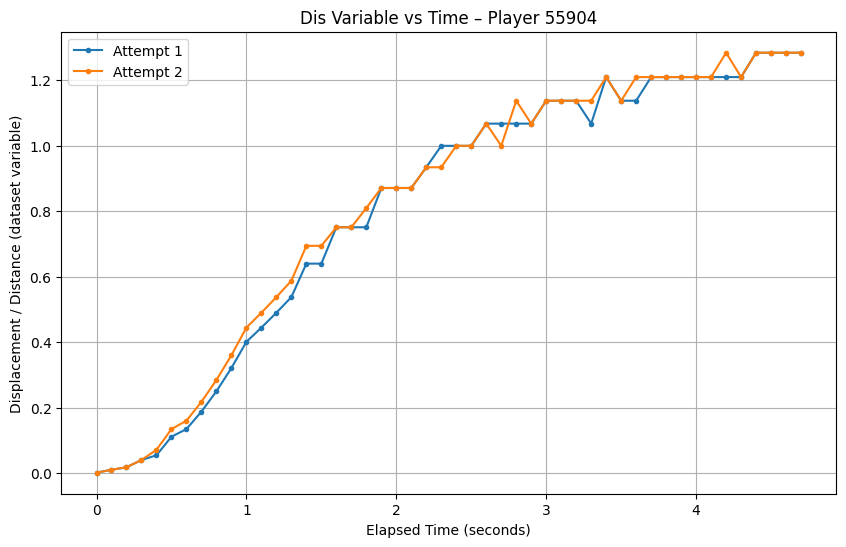

In [111]:
# Investigate the dis  varibale 

plt.figure(figsize=(10, 6))

for attempt, data in player_data.groupby("attempt"):
    plt.plot(
        data["elapsed_time"],
        data["dis"],
        marker="o",
        markersize=3,
        label=f"Attempt {attempt}"
    )

plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Displacement / Distance (dataset variable)")
plt.title("Dis Variable vs Time – Player 55904")
plt.legend()
plt.grid(True)
plt.show()

In [112]:
player_data[["attempt", "elapsed_time", "dis"]].head(15)

,attempt,elapsed_time,dis
367234,1,0.0,0.001571
367235,1,0.1,0.010062
367236,1,0.2,0.017778
367237,1,0.3,0.040000
367238,1,0.4,0.054456
367239,1,0.5,0.111117
367240,1,0.6,0.134444
367241,1,0.7,0.187781
367242,1,0.8,0.250000
367243,1,0.9,0.321113


### Observation – Distance Variable (`dis`)

The `dis` variable increases during the initial phase of both attempts. The two attempts show broadly similar patterns, with some differences during the middle and later phases.

The values appear to represent distance travelled between consecutive tracking observations rather than cumulative distance. Therefore, a higher value at a particular timestamp does not necessarily mean that the player covered more total distance during the entire attempt.

Further analysis is required to compare the total distance covered in both attempts.

In [113]:
# Let's calculate total distance now

player_data.groupby("attempt")["dis"].agg(
    ["count", "sum", "mean", "max"]
)

,count,sum,mean,max
attempt,,,,
1,48,38.928327,0.811007,1.284445
2,48,39.604519,0.825094,1.284445


### Distance Analysis – Player 55904

Both attempts contain 48 tracking observations.

- Attempt 1 has a total `dis` sum of 38.928327.
- Attempt 2 has a total `dis` sum of 39.604519.
- Attempt 2 has a slightly higher average distance per observation.
- Both attempts have the same maximum `dis` value of 1.284445.

**Observation:** Attempt 2 shows a slightly higher total recorded distance than Attempt 1. However, the maximum distance recorded in a single observation interval is identical in both attempts.

This is a preliminary comparison of one player's two attempts, not evidence of a general pattern across wide receivers.

From an Individual Case Study to the Full Wide-Receiver Tracking SampleThe previous section examined one player to understand how tracking variables behave across attempts. A single player cannot represent the full sample, so we now validate the filtered WR tracking data and investigate patterns across all available players and events.

**Validating the Filtered WR Tracking Dataset**

`Question:` Does the filtered dataset contain only the intended `WR players and 40-yard-dash` records, with expected identifiers and no missing tracking values?

`Why:` Feature engineering should begin only after we check that the filtering and sample structure are correct

In [114]:
# Validate our tracking sample (Before calculating features, let's confirm the data we're analysing. 
# Because, to ensure that We haven't accidentally included other positions, We haven't lost any players or events during filtering, 
# We know whether any variables contain missing values, Our dataset is ready for feature extraction.)

# Basic validation of our WR tracking dataset

print("Total observations:", len(wr_forty_data))

print("Unique players:", wr_forty_data["nfl_id"].nunique())

print("Unique events:", wr_forty_data["event_id"].nunique())

print("\nObservations per attempt:")
print(wr_forty_data["attempt"].value_counts().sort_index())

print("\nMissing values:")
print(wr_forty_data.isnull().sum())



Total observations: 8772
Unique players: 93
Unique events: 174

Observations per attempt:
attempt
1    4392
2    3625
3     607
4     148
Name: count, dtype: int64

Missing values:
draft_year     0
event_id       0
nfl_id         0
entity_type    0
time           0
drill_type     0
drill_name     0
attempt        0
x              0
y              0
s              0
a              0
dis            0
dir            0
dtype: int64


**Our validation output confirms that our filtered tracking dataset is internally consistent and ready for feature extraction.**

**Event-Level Feature Engineering**

`Question:` How can we summarize timestamped tracking observations into meaningful movement measurements for each recorded event?

`Why:` Each event contains many observations over time. Event-level summaries make events easier to compare while preserving a clear unit of analysis. We will summarize measures such as speed and acceleration, and derive movement summaries from coordinates. We will keep the original tracking data intact and create a separate feature table.

In [115]:
# Prepare the tracking data


# Create a separate copy
tracking = wr_forty_data.copy()

# Convert time into datetime format
tracking["time"] = pd.to_datetime(tracking["time"])

# Arrange observations chronologically within each event
tracking = tracking.sort_values(
    ["event_id", "time"]
)

# Calculate changes in X and Y positions
tracking["dx"] = tracking.groupby("event_id")["x"].diff()
tracking["dy"] = tracking.groupby("event_id")["y"].diff()

# Calculate distance between consecutive X-Y positions
tracking["step_distance_xy"] = np.hypot(
    tracking["dx"],
    tracking["dy"]
)

In [116]:
tracking[
    ["event_id", "attempt", "time",
     "x", "y", "dx", "dy", "step_distance_xy"]
].head(10)

,event_id,attempt,time,x,y,dx,dy,step_distance_xy
306135,20240302100700_1709410581872_000,1,2024-03-02 20:16:15.400,11.533333,-0.266667,NaN,NaN,NaN
306136,20240302100700_1709410581872_000,1,2024-03-02 20:16:15.500,11.566667,-0.300000,0.033333,-0.033333,0.047140
306137,20240302100700_1709410581872_000,1,2024-03-02 20:16:15.600,11.666667,-0.366667,0.100000,-0.066667,0.120185
306138,20240302100700_1709410581872_000,1,2024-03-02 20:16:15.700,11.766667,-0.433333,0.100000,-0.066667,0.120185
306139,20240302100700_1709410581872_000,1,2024-03-02 20:16:15.800,11.966667,-0.466667,0.200000,-0.033333,0.202759
306140,20240302100700_1709410581872_000,1,2024-03-02 20:16:15.900,12.200000,-0.533333,0.233333,-0.066667,0.242670
306141,20240302100700_1709410581872_000,1,2024-03-02 20:16:16.000,12.466667,-0.600000,0.266667,-0.066667,0.274874
306142,20240302100700_1709410581872_000,1,2024-03-02 20:16:16.100,12.833333,-0.666667,0.366667,-0.066667,0.372678
306143,20240302100700_1709410581872_000,1,2024-03-02 20:16:16.200,13.233333,-0.733333,0.400000,-0.066667,0.405518
306144,20240302100700_1709410581872_000,1,2024-03-02 20:16:16.300,13.733333,-0.766667,0.500000,-0.033333,0.501110



`X and Y:` Where the player is positioned.

`dx and dy:` How the player's position changed.

`Step_distance_xy:` How far the player moved between consecutive positions.

In [117]:
# Calculate the features

event_features = tracking.groupby("event_id").agg(

    # Player and event information
    nfl_id=("nfl_id", "first"),
    draft_year=("draft_year", "first"),
    attempt=("attempt", "first"),

    # Number and duration of observations
    observations=("time", "count"),
    start_time=("time", "min"),
    end_time=("time", "max"),

    # Speed features 
    mean_speed=("s", "mean"), # Average recorded speed during the event
    max_speed=("s", "max"),   # Highest recorded speed

    # Acceleration features
    mean_acceleration=("a", "mean"),   # Average recorded acceleration
    max_acceleration=("a", "max"),     # Highest recorded acceleration

    # Direction features
    initial_direction=("dir", "first"),    # Direction at the first observation
    final_direction=("dir", "last"),       # Direction at the last observation
   
    # Recorded distance features
    mean_dis=("dis", "mean"),          # Average recorded dis
    sum_dis=("dis", "sum"),            # Sum of recorded dis values
    max_dis=("dis", "max"),            # Highest recorded dis value

    # Distance calculated from X and Y coordinates
    path_length_xy=("step_distance_xy", "sum")    # Sum of distances between consecutive X-Y positions
    
).reset_index()

In [118]:
# Check our new table 


print("Feature table shape:", event_features.shape)

display(event_features.head())

print("\nMissing values:")
print(event_features.isnull().sum())

Feature table shape: (174, 17)


,event_id,nfl_id,draft_year,attempt,observations,start_time,end_time,mean_speed,max_speed,mean_acceleration,max_acceleration,initial_direction,final_direction,mean_dis,sum_dis,max_dis,path_length_xy
0,20240302100700_1709410581872_000,57231,2024,1,50,2024-03-02 20:16:15.400,2024-03-02 20:16:20.300,8.260333,10.986667,2.137315,6.314431,142.020779,89.840698,0.776012,38.800605,1.210000,40.858911
1,20240302100700_1709410633113_000,57201,2024,1,50,2024-03-02 20:17:07.100,2024-03-02 20:17:12.000,8.120467,11.260000,2.220364,5.929191,144.706652,90.291623,0.773285,38.664242,1.284445,40.139455
2,20240302100700_1709410684796_000,57606,2024,1,52,2024-03-02 20:17:58.600,2024-03-02 20:18:03.700,7.901538,10.716667,1.976107,5.489971,46.596681,90.801033,0.714373,37.147416,1.210000,40.537949
3,20240302100700_1709410743317_000,57154,2024,1,53,2024-03-02 20:18:57.000,2024-03-02 20:19:02.200,7.750881,10.700000,2.064694,5.638890,349.943724,90.340615,0.698980,37.045922,1.137778,40.663758
4,20240302100700_1709410796245_000,57256,2024,1,51,2024-03-02 20:19:49.900,2024-03-02 20:19:54.900,8.122222,11.163333,2.068665,4.938945,110.224859,89.828610,0.768262,39.181338,1.284444,40.990985



Missing values:
event_id             0
nfl_id               0
draft_year           0
attempt              0
observations         0
start_time           0
end_time             0
mean_speed           0
max_speed            0
mean_acceleration    0
max_acceleration     0
initial_direction    0
final_direction      0
mean_dis             0
sum_dis              0
max_dis              0
path_length_xy       0
dtype: int64


## **Feature Engineering – Event-Level Summary**

We transformed `8,772` individual tracking observations from `93 wide receivers` into an event-level feature table containing `174 rows` and `17 columns`.

Each row represents one recorded `40-yard`dash event.

We extracted summary features for speed, acceleration, direction and recorded distance. We also calculated the movement path length using consecutive X-Y coordinates.

The resulting table contains no missing values across its 17 columns.

This event-level dataset provides a structured foundation for comparing player movement characteristics across different attempts and athletes.

**Validating Distance Measurements at Event Level**

`Question:` Are event-level totals from the recorded dis variable similar to distances calculated from consecutive X-Y coordinates?

`Why:` Before choosing or relying on either distance measure in later analysis, we should compare them across all 174 events. Similar totals do not automatically mean the measures are identical in definition.

### **Step 1: Calculate the difference for every event**

We'll create three new columns:

`distance_difference:` difference between the two measurements.

`absolute_difference:` size of the difference, regardless of which is larger.

`percentage_difference:` difference expressed as a percentage of sum_dis.

In [119]:

# Create a copy of our feature table
distance_comparison = event_features.copy()

# Calculate the difference
distance_comparison["distance_difference"] = (
    distance_comparison["path_length_xy"] -
    distance_comparison["sum_dis"]
)

# Calculate absolute difference
distance_comparison["absolute_difference"] = (
    distance_comparison["distance_difference"].abs()
)

# Calculate percentage difference
distance_comparison["percentage_difference"] = (
    distance_comparison["absolute_difference"] /
    distance_comparison["sum_dis"]
) * 100

In [120]:
# Step 2: Display the comparison

distance_comparison[
    [
        "event_id",
        "nfl_id",
        "attempt",
        "sum_dis",
        "path_length_xy",
        "distance_difference",
        "absolute_difference",
        "percentage_difference"
    ]
].head(10)

,event_id,nfl_id,attempt,sum_dis,path_length_xy,distance_difference,absolute_difference,percentage_difference
0,20240302100700_1709410581872_000,57231,1,38.800605,40.858911,2.058306,2.058306,5.304829
1,20240302100700_1709410633113_000,57201,1,38.664242,40.139455,1.475214,1.475214,3.815447
2,20240302100700_1709410684796_000,57606,1,37.147416,40.537949,3.390533,3.390533,9.127238
3,20240302100700_1709410743317_000,57154,1,37.045922,40.663758,3.617835,3.617835,9.765813
4,20240302100700_1709410796245_000,57256,1,39.181338,40.990985,1.809648,1.809648,4.618647
5,20240302100700_1709410837287_000,57336,1,38.927329,41.923860,2.996531,2.996531,7.697757
6,20240302100700_1709410888215_000,57223,1,39.445002,40.783213,1.338211,1.338211,3.392600
7,20240302100700_1709410955889_000,57660,1,39.216189,41.044078,1.827888,1.827888,4.661056
8,20240302100700_1709411011359_000,57302,1,38.210223,40.713095,2.502872,2.502872,6.550269
9,20240302100700_1709411072573_000,57373,1,38.834992,40.852739,2.017747,2.017747,5.195693


In [121]:
# Step 3: Understand the overall differences

distance_comparison[
    [
        "sum_dis",
        "path_length_xy",
        "distance_difference",
        "absolute_difference",
        "percentage_difference"
    ]
].describe()

,sum_dis,path_length_xy,distance_difference,absolute_difference,percentage_difference
count,174.000000,174.000000,174.000000,174.000000,174.000000
mean,38.556903,40.683062,2.126159,2.146611,5.611733
std,0.920046,0.414052,0.828354,0.773486,2.128137
min,36.173693,39.703580,-1.012790,0.579408,1.425495
25%,37.912600,40.360538,1.595458,1.595458,4.039013
50%,38.552829,40.673267,2.140659,2.140659,5.516669
75%,39.182469,40.991658,2.697449,2.697449,7.093327
max,42.170362,42.059919,4.310372,4.310372,11.739495


In [122]:
# Step 4: Count which measurement is larger

print(
    "Events where path_length_xy is higher:",
    (distance_comparison["distance_difference"] > 0).sum()
)

print(
    "Events where sum_dis is higher:",
    (distance_comparison["distance_difference"] < 0).sum()
)

print(
    "Events where both are equal:",
    (distance_comparison["distance_difference"] == 0).sum()
)

Events where path_length_xy is higher: 172
Events where sum_dis is higher: 2
Events where both are equal: 0


### Distance Measurement Comparison – 174 Events

To investigate the consistency of two distance-related measurements, I compared the sum of the recorded `dis` values (`sum_dis`) with the distance calculated from consecutive X-Y coordinates (`path_length_xy`).

Across 174 recorded events:

- Mean `sum_dis`: 38.557
- Mean `path_length_xy`: 40.683
- Mean absolute difference: 2.147
- Mean percentage difference relative to `sum_dis`: 5.61%

The coordinate-based path length was higher in 172 events, while `sum_dis` was higher in only 2 events. No events had exactly equal values.

**Preliminary observation:** The two distance measurements show a consistent difference across this sample. Further investigation of their definitions, units and calculation methods is necessary before deciding which measurement is appropriate for subsequent analysis.

## **Comparing Distance Measurements at Individual Observations**

`Question:` At the tracking-observation level, how closely does recorded dis match the distance calculated from consecutive X-Y coordinates?

`Why:` Event-level totals can hide differences between individual steps, so we inspect the measurements at their original observation scale

#### **Now we'll compare the two measurements at the individual tracking-observation level.**


In [123]:
# Create a separate comparison table

step_comparison = tracking.dropna(
    subset=["step_distance_xy"]
).copy()

In [124]:
# Compare the two measurements

step_comparison[
    ["event_id", "attempt", "time", "dis", "step_distance_xy"]
].head(15)

,event_id,attempt,time,dis,step_distance_xy
306136,20240302100700_1709410581872_000,1,2024-03-02 20:16:15.500,0.001571,0.047140
306137,20240302100700_1709410581872_000,1,2024-03-02 20:16:15.600,0.010943,0.120185
306138,20240302100700_1709410581872_000,1,2024-03-02 20:16:15.700,0.010943,0.120185
306139,20240302100700_1709410581872_000,1,2024-03-02 20:16:15.800,0.040015,0.202759
306140,20240302100700_1709410581872_000,1,2024-03-02 20:16:15.900,0.054626,0.242670
306141,20240302100700_1709410581872_000,1,2024-03-02 20:16:16.000,0.071250,0.274874
306142,20240302100700_1709410581872_000,1,2024-03-02 20:16:16.100,0.134518,0.372678
306143,20240302100700_1709410581872_000,1,2024-03-02 20:16:16.200,0.160062,0.405518
306144,20240302100700_1709410581872_000,1,2024-03-02 20:16:16.300,0.250002,0.501110
306145,20240302100700_1709410581872_000,1,2024-03-02 20:16:16.400,0.284447,0.534374


#### **Now let's calculate the difference across all individual observations.**

In [125]:
step_comparison["step_difference"] = (
    step_comparison["step_distance_xy"] -
    step_comparison["dis"]
)

step_comparison["absolute_step_difference"] = (
    step_comparison["step_difference"].abs()
)

In [126]:
step_comparison[
    ["dis", "step_distance_xy",
     "step_difference",
     "absolute_step_difference"]
].describe()

,dis,step_distance_xy,step_difference,absolute_step_difference
count,8598.000000,8598.000000,8598.000000,8598.000000
mean,0.780210,0.823314,0.043104,0.114555
std,0.425230,0.320848,0.128704,0.072792
min,0.000000,0.000000,-0.215876,0.000000
25%,0.419365,0.647596,-0.071111,0.062222
50%,0.934444,0.966667,0.032222,0.109496
75%,1.137778,1.066667,0.160000,0.162743
max,1.398427,1.182551,0.270940,0.270940


In [127]:
print(
    "XY distance higher:",
    (step_comparison["step_difference"] > 0).sum()
)

print(
    "Recorded dis higher:",
    (step_comparison["step_difference"] < 0).sum()
)

print(
    "Equal:",
    (step_comparison["step_difference"] == 0).sum()
)

XY distance higher: 4786
Recorded dis higher: 3582
Equal: 230


### **Individual Distance Comparison – 8,598 Observations**

I compared the recorded `dis` variable with the distance calculated from consecutive X-Y coordinates (`step_distance_xy`) across 8,598 eligible tracking observations.

Results:

- XY distance was higher in 4,786 observations (55.66%).
- Recorded `dis` was higher in 3,582 observations (41.66%).
- Both measurements were equal in 230 observations (2.67%).

The mean XY distance was 0.823314, compared with 0.780210 for `dis`. The mean absolute difference was 0.114555.

**Preliminary observation:** The two measurements differ at most individual tracking intervals, and the direction of the difference varies. However, the coordinate-based distance has a higher mean in this sample.

Further investigation of the variable definitions, units and calculation methods is required before interpreting these differences.

**Distribution of Individual Distance Differences**

`Question:` How are the individual differences distributed around zero?

`Why:` A histogram summarizes the frequency and direction of differences, helping us see whether the measures commonly agree or one tends to be larger

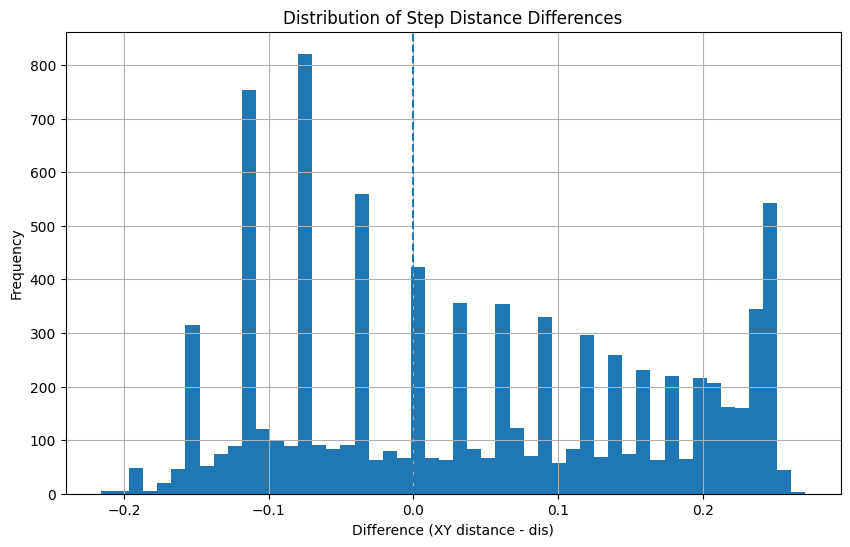

In [128]:
# We are plotting a Histogram to understand the distribution of differences between dis and step_distance_xy.


plt.figure(figsize=(10, 6))

plt.hist(step_comparison["step_difference"], bins=50)

plt.axvline(0, linestyle="--")

plt.xlabel("Difference (XY distance - dis)")
plt.ylabel("Frequency")
plt.title("Distribution of Step Distance Differences")

plt.grid(True)
plt.show()

- Bars to the right of zero = XY distance is higher.
- Bars to the left of zero = dis is higher.
- Values around zero = the two measurements are close.

#### **Relationship Between the Two Distance Measurements**

`Question:` How are recorded dis and X-Y-derived step distance related across observations?

`Why:` A scatter plot shows the relationship between two variables directly, complementing the histogram of their differences

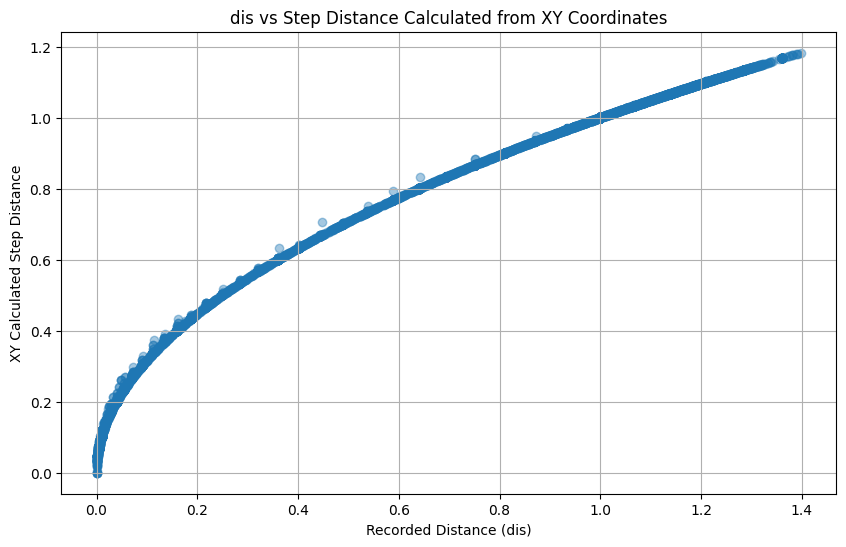

In [129]:
# Plotting a scatter plot to compare the two distance measurements.

plt.figure(figsize=(10, 6))

plt.scatter(
    step_comparison["dis"],
    step_comparison["step_distance_xy"],
    alpha=0.4
)

plt.xlabel("Recorded Distance (dis)")
plt.ylabel("XY Calculated Step Distance")
plt.title("dis vs Step Distance Calculated from XY Coordinates")

plt.grid(True)
plt.show()

#### **Observation from both graphs**

**Graph 1 — Histogram of Step Distance Differences**

The differences between `dis` and `step_distance_xy` are distributed on both sides of zero. `XY distance is higher in 4,786` observations, `dis is higher in 3,582` observations, and `230 observations have equal values`. The differences therefore vary in direction, although XY distance has a higher mean.


**Graph 2 — Scatter Plot of dis vs step_distance_xy**

The scatter plot shows a `strong positive` relationship between the two distance measurements. As recorded `dis increases, the XY-calculated step distance also increases`. The points are tightly grouped, suggesting the two measurements track each other closely, despite not being identical.


- **The histogram shows us that the differences between the measurements vary in magnitude and direction.**
- **The scatter plot shows us that, despite those differences, both measurements generally move together.**

#### **Investigating Distance-Measurement Differences Across Speed**

`Question:` Does the difference between recorded dis and the X-Y-derived step distance vary with speed?

`Why:` The two distance measures were positively related but not identical. We now investigate whether their signed difference changes across the speed range. The difference is defined as step_distance_xy - dis: positive means the X-Y-derived value is larger, negative means recorded dis is larger, and zero means they match.

In [130]:
# Creating a Difference Column

tracking["step_difference"] = (
    tracking["step_distance_xy"] - tracking["dis"]
)

**This creates a new column in tracking:**
- Positive value → XY-calculated distance is greater.
- Negative value → recorded dis is greater.
- Zero → both distances are equal.

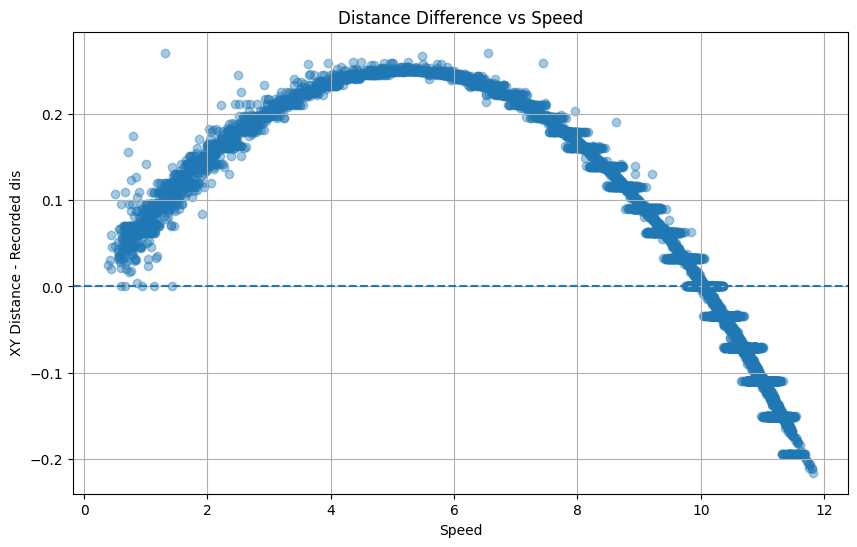

In [131]:
# Plot difference against speed

plt.figure(figsize=(10, 6))

plt.scatter(
    tracking["s"],
    tracking["step_difference"],
    alpha=0.4
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Speed")
plt.ylabel("XY Distance - Recorded dis")
plt.title("Distance Difference vs Speed")

plt.grid(True)
plt.show()

#### **The graph tells us how the distance-measurement discrepancy behaves at different speeds.**

**At low to moderate speeds:**

- Most differences are `positive`.
- This means `step_distance_xy` is generally greater than recorded `dis`.
- The difference increases and reaches its highest values around speed `4–5.5`.


**As speed increases further:**

- The difference gradually decreases.
- Around speed `10`, the difference approaches zero.
- At higher speeds, many differences become `negative`.

This means recorded `dis` becomes greater than the `XY-calculated` step distance for many observations.

So the pattern is not a simple increasing or decreasing relationship. It looks like an arched, non-linear pattern.

**The relationship between speed and the difference in distance measurements appears non-linear. At low-to-moderate speeds, XY-calculated step distance is generally higher than recorded distance. As speed increases, the difference decreases, approaches zero, and becomes negative at higher speeds, where recorded distance often exceeds the XY-calculated value.**

In [132]:
# We'll divide speed into ranges and calculate the average difference within each range.

tracking["speed_group"] = pd.cut(
    tracking["s"],
    bins=[0, 2, 4, 6, 8, 10, 12],
    right=False
)

speed_analysis = tracking.groupby("speed_group", observed=True).agg(
    observations=("step_difference", "count"),
    mean_difference=("step_difference", "mean"),
    mean_absolute_difference=("step_difference", lambda x: x.abs().mean())
)

speed_analysis



,observations,mean_difference,mean_absolute_difference
speed_group,,,
"[0, 2)",643,0.093357,0.093357
"[2, 4)",629,0.198376,0.198376
"[4, 6)",627,0.247261,0.247261
"[6, 8)",868,0.210363,0.210363
"[8, 10)",1969,0.078751,0.078751
"[10, 12)",3862,-0.079463,0.079609


The difference between recorded `dis` and `XY-calculated` step distance is not constant across speed levels. It increases through the lower-to-middle speed ranges, reaches its highest average around `4–6`, and then declines, becoming negative in the `10–12` speed range.

Extending Movement Analysis Across All `174 Events` The individual-player case study helped us understand the tracking variables. We now examine whether descriptive patterns across movement observations appear in the wider `WR` sample. This analysis is exploratory and does not establish a player-level performance ranking.

How does distance-measurement discrepancy vary across low, medium, and high speed phases?

We group observations into broad speed ranges to summarize the discrepancy. These bins are a descriptive aid, not natural or validated movement categories.

In [133]:
# Create speed phases

tracking["speed_phase"] = pd.cut(
    tracking["s"],
    bins=[0, 4, 8, 12],
    labels=["Low Speed", "Medium Speed", "High Speed"],
    right=False
)

In [134]:
# Summarize each phase

phase_analysis = tracking.groupby("speed_phase", observed=True).agg(
    observations=("step_difference", "count"),
    mean_difference=("step_difference", "mean"),
    mean_absolute_difference=("step_difference", lambda x: x.abs().mean())
)

phase_analysis

,observations,mean_difference,mean_absolute_difference
speed_phase,,,
Low Speed,1272,0.145288,0.145288
Medium Speed,1495,0.225838,0.225838
High Speed,5831,-0.026038,0.079319


#### **What did we discover?**

`Low speed`
- Average difference ≈ 0.145
- XY-calculated distance is higher than recorded dis on average.

`Medium speed`
- Average difference ≈ 0.226
- This is the largest average difference among our three speed phases.
- The two distance measurements diverge the most on average in this phase.

`High speed`
- Mean difference ≈ −0.026
- The signed mean is close to zero, meaning the differences in both directions partially cancel.
- But mean absolute difference is 0.079, which is the smallest of the three phases.

So, based on these results, the two distance measurements appear closer together during high-speed observations, and their largest average discrepancy occurs during medium-speed observations.

#### **Now we'll calculate how often each distance measurement is higher within each speed phase.**


Our difference variable is:

`step_difference = step_distance_xy - dis`


So we can classify each observation into three conditions:

- step_difference > 0 → XY distance is higher
- step_difference < 0 → recorded dis is higher
- step_difference == 0 → both are equal

In [135]:
# Count each condition

phase_comparison = tracking.groupby("speed_phase", observed=True).agg(
    xy_higher=("step_difference", lambda x: (x > 0).sum()),
    recorded_higher=("step_difference", lambda x: (x < 0).sum()),
    equal=("step_difference", lambda x: (x == 0).sum()),
    observations=("step_difference", "count")
)

phase_comparison

,xy_higher,recorded_higher,equal,observations
speed_phase,,,,
Low Speed,1267,0,5,1272
Medium Speed,1495,0,0,1495
High Speed,2024,3582,225,5831


In [136]:
# Calculate percentages

phase_comparison["xy_higher_pct"] = (
    phase_comparison["xy_higher"] / phase_comparison["observations"] * 100
)

phase_comparison["recorded_higher_pct"] = (
    phase_comparison["recorded_higher"] / phase_comparison["observations"] * 100
)

phase_comparison["equal_pct"] = (
    phase_comparison["equal"] / phase_comparison["observations"] * 100
)

phase_comparison

,xy_higher,recorded_higher,equal,observations,xy_higher_pct,recorded_higher_pct,equal_pct
speed_phase,,,,,,,
Low Speed,1267,0,5,1272,99.606918,0.000000,0.393082
Medium Speed,1495,0,0,1495,100.000000,0.000000,0.000000
High Speed,2024,3582,225,5831,34.711027,61.430286,3.858686


### Summary Observation

The difference between recorded distance (`dis`) and XY-calculated distance (`step_distance_xy`) varied across speed phases.

- During low-speed observations, XY-calculated distance was higher in 99.61% of observations.
- During medium-speed observations, XY-calculated distance was higher in all observations (100%).
- During high-speed observations, recorded distance was higher in 61.43% of observations, while XY-calculated distance was higher in 34.71% and both were equal in 3.86%.

The mean absolute difference was highest during medium speed (0.2258) and lowest during high speed (0.0793). This suggests that the two distance measurements were closer during high-speed movement, while their discrepancy was larger during medium-speed movement.

These are exploratory findings and do not establish the cause of the differences.

#### **Investigating Acceleration Across All 174 Events**

`Question:` How does maximum acceleration vary across recorded 40-yard-dash events, and are any events unusually high relative to the rest?

`Why:` Comparing event-level acceleration summaries helps identify observations that deserve closer inspection. A high value is not automatically an error or an outlier; we will inspect the underlying time series before making that judgment.

In [137]:
event_features[["mean_acceleration", "max_acceleration"]].describe()

,mean_acceleration,max_acceleration
count,174.000000,174.000000
mean,2.128623,5.815055
std,0.113393,0.686022
min,1.846696,4.558173
25%,2.053379,5.386633
50%,2.124675,5.784959
75%,2.192876,6.129320
max,2.607891,9.779181


**Acceleration Distribution Across 174 Events**

We examined the mean and maximum acceleration across all `174`recorded events.

- Mean acceleration had an overall average of `2.1286`, with a standard deviation of `0.1134`.

- The median mean-acceleration value `(2.1247)` was close to the overall mean, indicating a relatively centered distribution.

- Maximum acceleration had an average of `5.8151` and a higher standard deviation of `0.6860`.

- Maximum acceleration varied more considerably across events than mean acceleration.

**Preliminary observation:** Average acceleration values appear relatively consistent across events, while peak acceleration shows greater variability. This indicates that events with similar average acceleration may still reach different peak acceleration levels.

#### **Distribution of Maximum Acceleration**

`Question:` What does the distribution of event-level maximum acceleration look like, and are any values unusually high?

`Why:` This helps identify events for follow-up inspection. Unusual values are candidates for investigation—not automatic data errors

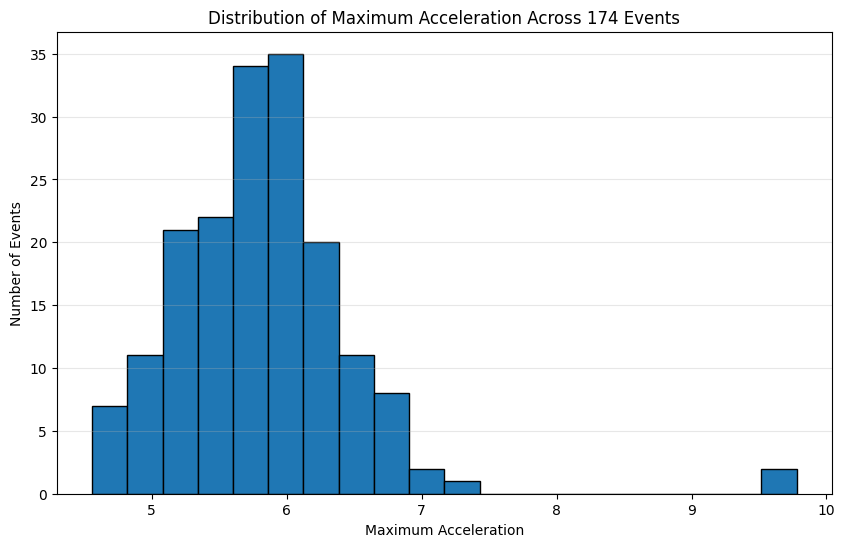

In [138]:
# We'll visualize the distribution of maximum acceleration across all 174 events.

plt.figure(figsize=(10, 6))

plt.hist(
    event_features["max_acceleration"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Maximum Acceleration")
plt.ylabel("Number of Events")
plt.title("Distribution of Maximum Acceleration Across 174 Events")
plt.grid(axis="y", alpha=0.3)

plt.show()

**There is an unusually high maximum acceleration value in the histogram, separated from the main distribution.**

- Most events have maximum acceleration values concentrated roughly between `5.4 and 6.5`.
- The distribution peaks around `5.8 – 6.1`.
- There is one value near 9.78, which is far away from the rest of the observations.

#### **Identifying the Event With the Highest Maximum Acceleration**

`Question:` Which player, attempt, and event produced the largest recorded maximum acceleration?

`Why:` We need to locate the event so we can inspect its original time-series observations

In [139]:
# identify the event (This will tell us which player, event, attempt, and draft year produced that unusually high acceleration.)

event_features.loc[
    event_features["max_acceleration"].idxmax()
]

event_id             20240302100800_1709421008364_000
nfl_id                                          57152
draft_year                                       2024
attempt                                             2
observations                                       47
start_time                 2024-03-02 23:10:01.100000
end_time                   2024-03-02 23:10:05.700000
mean_speed                                   8.827589
max_speed                                   11.143333
mean_acceleration                            2.607891
max_acceleration                             9.779181
initial_direction                           15.407704
final_direction                             90.725881
mean_dis                                     0.854263
sum_dis                                     40.150379
max_dis                                      1.284444
path_length_xy                              41.095868
Name: 39, dtype: object

#### **Inspecting the High-Acceleration Event in the Original Tracking Data**

`Question:` Is the unusually high acceleration isolated, or does it form part of a broader acceleration profile?

`Why:` Looking at the original observations helps us avoid judging an event from a single summary value. We retain the event unless evidence supports excluding it

In [140]:
# But before calling it an outlier, let's inspect the actual tracking data
# First, extract this event from our original tracking data:
# This will give us the 47 individual observations for this player's attempt.


outlier_event_id = "20240302100800_1709421008364_000"

outlier_data = wr_forty_data[
    wr_forty_data["event_id"] == outlier_event_id
].copy()

outlier_data.sort_values("time")

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
265663,2024,20240302100800_1709421008364_000,57152,PLAYER,2024-03-02T23:10:01.100,FORTY_YARD_DASH,FORTY_YARD_DASH,2,10.800000,0.833333,1.320000,2.041930,0.010062,15.407704
265664,2024,20240302100800_1709421008364_000,57152,PLAYER,2024-03-02T23:10:01.200,FORTY_YARD_DASH,FORTY_YARD_DASH,2,10.833333,0.966667,1.183333,3.712856,0.017812,26.925397
265665,2024,20240302100800_1709421008364_000,57152,PLAYER,2024-03-02T23:10:01.300,FORTY_YARD_DASH,FORTY_YARD_DASH,2,10.933333,1.000000,1.183333,5.487806,0.010062,58.148868
265666,2024,20240302100800_1709421008364_000,57152,PLAYER,2024-03-02T23:10:01.400,FORTY_YARD_DASH,FORTY_YARD_DASH,2,11.066667,1.033333,1.583333,7.077329,0.017812,82.381454
265667,2024,20240302100800_1709421008364_000,57152,PLAYER,2024-03-02T23:10:01.500,FORTY_YARD_DASH,FORTY_YARD_DASH,2,11.366667,0.933333,2.540000,8.360432,0.090554,99.746635
265668,2024,20240302100800_1709421008364_000,57152,PLAYER,2024-03-02T23:10:01.600,FORTY_YARD_DASH,FORTY_YARD_DASH,2,11.666667,0.866667,3.440000,9.233736,0.090110,104.520535
265669,2024,20240302100800_1709421008364_000,57152,PLAYER,2024-03-02T23:10:01.700,FORTY_YARD_DASH,FORTY_YARD_DASH,2,12.066667,0.766667,4.403333,9.725194,0.160312,106.761554
265670,2024,20240302100800_1709421008364_000,57152,PLAYER,2024-03-02T23:10:01.800,FORTY_YARD_DASH,FORTY_YARD_DASH,2,12.566667,0.633333,5.476667,9.779181,0.250631,107.100165
265671,2024,20240302100800_1709421008364_000,57152,PLAYER,2024-03-02T23:10:01.900,FORTY_YARD_DASH,FORTY_YARD_DASH,2,13.166667,0.433333,6.546667,9.287476,0.362215,107.604633
265672,2024,20240302100800_1709421008364_000,57152,PLAYER,2024-03-02T23:10:02.000,FORTY_YARD_DASH,FORTY_YARD_DASH,2,13.833333,0.200000,7.446667,8.326659,0.447767,107.072565


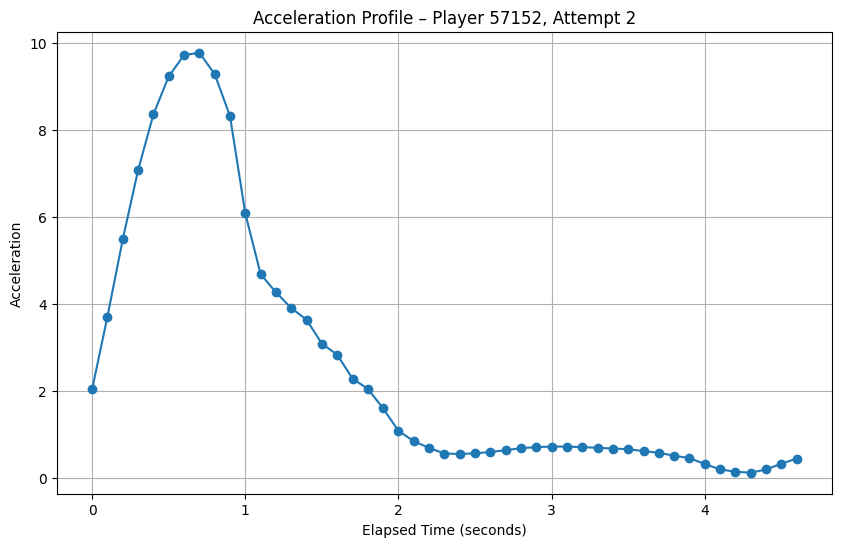

In [141]:
# Next, let's visualize acceleration over time:


outlier_data["time"] = pd.to_datetime(outlier_data["time"])

outlier_data["elapsed_time"] = (
    outlier_data["time"] - outlier_data["time"].min()
).dt.total_seconds()

plt.figure(figsize=(10, 6))

plt.plot(
    outlier_data["elapsed_time"],
    outlier_data["a"],
    marker="o"
)

plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Acceleration")
plt.title("Acceleration Profile – Player 57152, Attempt 2")
plt.grid(True)
plt.show()

**What we observe from Player `57152 — Attempt 2`**

`Initial acceleration:` Starts around 2.0 and rises rapidly.

`Peak acceleration:` Reaches approximately 9.78 around 0.6–0.7 seconds.

`After the peak:` Acceleration drops sharply, then gradually decreases.

`Later phase:` Acceleration remains relatively low, around 0.5–0.7 for much of the run, eventually approaching zero.

### **Our next step**

Let's examine speed for this same event and attempt.

`Why?` Because acceleration represents the rate at which speed changes. If acceleration reaches a very high value, we should investigate whether the player's speed increases correspondingly during that period.

`Next investigation:` Validate the unusually high acceleration using the speed profile.

#### **Cross-Checking the High-Acceleration Event With Its Speed Profile**

`Question:` Does the speed profile change in a way that is broadly consistent with the high acceleration recorded for this event?

`Why:` Acceleration is related to the rate of change in speed, so the speed time series provides a useful consistency check. A plot alone cannot fully validate sensor accuracy

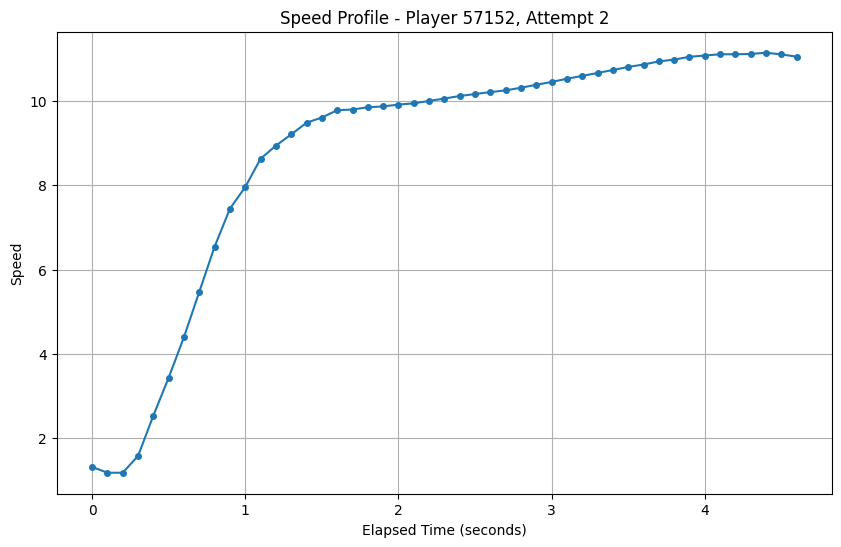

In [142]:
# Extract speed data for the same event
outlier_data = wr_forty_data[
    wr_forty_data["event_id"] == outlier_event_id
].copy()

# Convert time into datetime
outlier_data["time"] = pd.to_datetime(outlier_data["time"])

# Calculate elapsed time from the beginning of the attempt
outlier_data["elapsed_time"] = (
    outlier_data["time"] - outlier_data["time"].min()
).dt.total_seconds()

# Sort observations chronologically
outlier_data = outlier_data.sort_values("time")

# Plot speed profile
plt.figure(figsize=(10, 6))

plt.plot(
    outlier_data["elapsed_time"],
    outlier_data["s"],
    marker="o",
    markersize=4
)

plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Speed")
plt.title("Speed Profile - Player 57152, Attempt 2")
plt.grid(True)

plt.show()

**What we observe from the speed graph**

- At the beginning, speed is around 1.2–1.3.
- During the first second, speed increases rapidly.
- Around 1–1.6 seconds, speed reaches approximately 9.8.
- After that, speed continues to increase, but much more slowly.
- Around 4 seconds, it reaches approximately 11.1–11.2.
- Towards the end, speed becomes nearly stable, with a very slight decrease.



**2. Compare acceleration and speed together**

`Acceleration graph`
Acceleration rises sharply, reaches its peak around 0.6–0.7 seconds, and then declines.

`Speed graph`
Speed increases rapidly during that same early phase, then continues increasing more gradually.


This is a physically consistent pattern: high acceleration during the early phase corresponds with a rapid increase in speed. As acceleration decreases, speed is still increasing, but at a slower rate.


**3. Does this look like a suspicious data point?**

Based on these two graphs:
- The speed curve is smooth.
- There is no obvious sudden jump or isolated spike in speed.
- The high acceleration occurs during the rapid early increase in speed.
- The acceleration profile also changes smoothly rather than showing a single isolated spike.

Therefore, we don't have sufficient evidence to call this a bad data point or tracking error. It appears more consistent with a genuine high-acceleration movement profile, although we cannot fully validate the measurement from these graphs alone.


**4. Our conclusion so far**

We identified an event with unusually high maximum acceleration `(9.779)`. After inspecting its acceleration and speed profiles, we found that its high acceleration occurs during a rapid increase in speed, with no obvious visual irregularity in the speed profile.

So, for now, we retain this event rather than remove it.

### **Investigating Multiple High-Acceleration Events**

`Question:` Are there multiple events with unusually high maximum acceleration, or is the event we previously investigated an isolated case?

`Why:` We previously examined the event with the highest recorded maximum acceleration (9.779). Although its acceleration and speed profiles appeared broadly consistent, investigating only one event is insufficient to understand the overall distribution.

We will now identify other events with unusually high maximum acceleration relative to the rest of the sample. Rather than choosing an arbitrary threshold, we will use the Interquartile Range (IQR) method to identify candidate events for further inspection.

These candidates will be treated as observations requiring investigation, not automatically as errors or events to be removed.

**Step 1 — Identify candidate high-acceleration events**

In [143]:
# Calculate the IQR for maximum acceleration

Q1 = event_features["max_acceleration"].quantile(0.25)
Q3 = event_features["max_acceleration"].quantile(0.75)

IQR = Q3 - Q1

upper_fence = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper Fence:", upper_fence)

Q1: 5.386633287
Q3: 6.129320084
IQR: 0.7426867969999993
Upper Fence: 7.243350279499999


*So, under the IQR rule, any event whose maximum acceleration is greater than 7.2434 becomes a candidate for further inspection.*

**2. Next step: identify all candidate events**

How many events exceed this threshold, and which events are they?

In [144]:
# Identify events whose maximum acceleration exceeds the IQR upper fence

high_acceleration_events = event_features[
    event_features["max_acceleration"] > upper_fence
].copy()

# Sort candidates from highest to lowest maximum acceleration
high_acceleration_events = high_acceleration_events.sort_values(
    "max_acceleration",
    ascending=False
)

high_acceleration_events[
    ["event_id", "nfl_id", "draft_year", "attempt", "max_acceleration"]
]

,event_id,nfl_id,draft_year,attempt,max_acceleration
39,20240302100800_1709421008364_000,57152,2024,2,9.779181
18,20240302100700_1709411590925_000,57256,2024,2,9.742838


### **Investigating Maximum Acceleration Across Attempts**

`Question:` Do events from Attempt 2 generally exhibit higher maximum acceleration than events from other attempts, or are the two high-acceleration events isolated cases?

`Why:` Both events identified by the IQR method belong to Attempt 2. However, two observations alone are not enough to establish that this attempt has a different acceleration pattern. We will compare the distribution of maximum acceleration across all recorded attempts to determine whether the high values are part of a broader pattern or individual cases.

In [145]:
attempt_acceleration_summary = (
    event_features
    .groupby("attempt")["max_acceleration"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

attempt_acceleration_summary

,count,mean,median,std,min,max
attempt,,,,,,
1,87,5.751074,5.745055,0.560057,4.558173,7.222170
2,72,5.888557,5.835648,0.829534,4.804013,9.779181
3,12,5.758984,5.850920,0.601327,4.795319,6.645220
4,3,6.130757,6.062773,0.513183,5.654955,6.674543


**What can we conclude so far?**

- We identified 2 candidate events above the IQR upper fence.

- Both belong to Attempt 2.

- Attempt 2 has the highest maximum acceleration, but its average is only modestly higher than the other attempts.

- Attempts 3 and 4 have very small sample sizes (12 and 3 events), so comparisons involving them should be treated cautiously.

So, at this stage, we have a concentration of high-acceleration candidates in Attempt 2, not evidence that Attempt 2 inherently produces greater acceleration.

### **Investigating High-Acceleration Events Across Draft Years and Attempts**

`Question:` How are the high-acceleration candidate events distributed across draft years and attempts, relative to the total number of events in each group?

`Why:` Both candidate events belong to draft year 2024 and Attempt 2. However, the number of events available may differ across draft years and attempts. Comparing candidate counts with total event counts will help us determine whether these observations are concentrated in a particular group or whether the pattern may be influenced by sample size.

In [146]:
# Count total events and high-acceleration candidates by draft year and attempt

event_counts = event_features.groupby(
    ["draft_year", "attempt"]
).size().rename("total_events")

high_acc_counts = high_acceleration_events.groupby(
    ["draft_year", "attempt"]
).size().rename("high_acceleration_events")

comparison = pd.concat(
    [event_counts, high_acc_counts], axis=1
).fillna(0)

comparison["high_acceleration_events"] = (
    comparison["high_acceleration_events"].astype(int)
)

comparison["percentage_flagged"] = (
    comparison["high_acceleration_events"] / comparison["total_events"] * 100
)

comparison.sort_values(
    ["draft_year", "attempt"]
)

total_events  high_acceleration_events  percentage_flagged
draft_year attempt                                                            
2023       1                  28                         0            0.000000
           2                  24                         0            0.000000
           3                   6                         0            0.000000
           4                   3                         0            0.000000
2024       1                  26                         0            0.000000
           2                  19                         2           10.526316
           3                   3                         0            0.000000
2025       1                  33                         0            0.000000
           2                  29                         0            0.000000
           3                   3                         0            0.000000

### **Investigating the Second High-Acceleration Event**

`Question:` Does the second event with unusually high maximum acceleration exhibit a similar acceleration and speed profile to the first event we investigated?

`Why:` The IQR analysis identified two candidate events, both from 2024 Attempt 2. We previously inspected the first event and observed a relatively smooth acceleration profile, with the increase in speed broadly consistent with the recorded acceleration. We will now examine the second event using the same approach to determine whether the observed pattern is similar or different.

This comparison may help us understand whether the high maximum acceleration values occur within broader movement profiles or appear as isolated peaks. The events will remain flagged for investigation and will not be removed solely because of their magnitude.

In [147]:
# Select the second-highest acceleration candidate event

second_event_id = high_acceleration_events.iloc[1]["event_id"]

second_event_data = wr_forty_data[
    wr_forty_data["event_id"] == second_event_id
].copy()

second_event_data

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
270780,2024,20240302100700_1709411590925_000,57256,PLAYER,2024-03-02T20:33:05.200,FORTY_YARD_DASH,FORTY_YARD_DASH,2,10.800000,-0.566667,0.606667,2.362414,0.001111,72.458674
270781,2024,20240302100700_1709411590925_000,57256,PLAYER,2024-03-02T20:33:05.300,FORTY_YARD_DASH,FORTY_YARD_DASH,2,10.866667,-0.533333,0.820000,2.921531,0.004581,79.736657
270782,2024,20240302100700_1709411590925_000,57256,PLAYER,2024-03-02T20:33:05.400,FORTY_YARD_DASH,FORTY_YARD_DASH,2,11.000000,-0.533333,1.386667,4.542570,0.017778,85.728008
270783,2024,20240302100700_1709411590925_000,57256,PLAYER,2024-03-02T20:33:05.500,FORTY_YARD_DASH,FORTY_YARD_DASH,2,11.133333,-0.500000,1.763333,5.637597,0.017812,88.375791
270784,2024,20240302100700_1709411590925_000,57256,PLAYER,2024-03-02T20:33:05.600,FORTY_YARD_DASH,FORTY_YARD_DASH,2,11.400000,-0.533333,2.510000,6.768256,0.071120,91.141199
270785,2024,20240302100700_1709411590925_000,57256,PLAYER,2024-03-02T20:33:05.700,FORTY_YARD_DASH,FORTY_YARD_DASH,2,11.666667,-0.533333,3.243333,7.951168,0.071111,92.118918
270786,2024,20240302100700_1709411590925_000,57256,PLAYER,2024-03-02T20:33:05.800,FORTY_YARD_DASH,FORTY_YARD_DASH,2,12.133333,-0.566667,4.363333,8.963265,0.217781,93.021991
270787,2024,20240302100700_1709411590925_000,57256,PLAYER,2024-03-02T20:33:05.900,FORTY_YARD_DASH,FORTY_YARD_DASH,2,12.633333,-0.600000,5.366667,9.580300,0.250002,93.383181
270788,2024,20240302100700_1709411590925_000,57256,PLAYER,2024-03-02T20:33:06.000,FORTY_YARD_DASH,FORTY_YARD_DASH,2,13.266667,-0.633333,6.456667,9.742838,0.401113,93.196238
270789,2024,20240302100700_1709411590925_000,57256,PLAYER,2024-03-02T20:33:06.100,FORTY_YARD_DASH,FORTY_YARD_DASH,2,13.966667,-0.666667,7.473333,9.400229,0.490001,93.144397


#### **Examining the Acceleration Profile of the Second Candidate Event**

`Question:` How does acceleration change throughout the second high-acceleration event, and is the maximum acceleration part of a continuous movement profile or an isolated spike?

`Why:` The raw observations suggest that acceleration initially increases and then decreases. Visualizing acceleration over elapsed time will help us examine the shape of this profile, identify the timing of its peak, and determine whether the high value appears as part of a continuous pattern or an abrupt isolated observation.

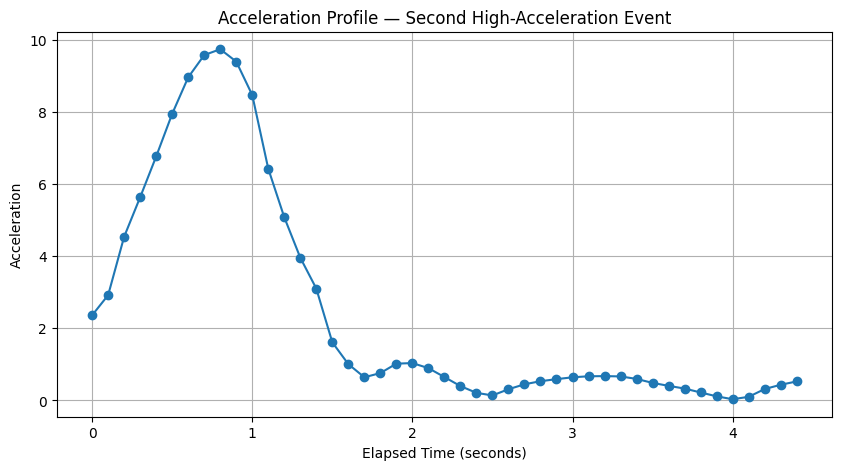

In [148]:
# Convert timestamp to datetime
second_event_data["time"] = pd.to_datetime(second_event_data["time"])

# Sort observations chronologically
second_event_data = second_event_data.sort_values("time").copy()

# Calculate elapsed time from the beginning of the event
second_event_data["elapsed_time"] = (
    second_event_data["time"] - second_event_data["time"].min()
).dt.total_seconds()

# Plot acceleration over time
plt.figure(figsize=(10, 5))

plt.plot(
    second_event_data["elapsed_time"],
    second_event_data["a"],
    marker="o"
)

plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Acceleration")
plt.title("Acceleration Profile — Second High-Acceleration Event")
plt.grid(True)
plt.show()

**Observation:** The second high-acceleration candidate `(Player 57256, Attempt 2)` exhibited a continuous acceleration profile. Acceleration initially increased rapidly, reached a peak of approximately `9.74`, and subsequently declined sharply before remaining relatively low during the later portion of the event. The maximum acceleration did not appear as an isolated single-point spike in the plotted profile.

This pattern is broadly similar to the first high-acceleration event we investigated. Therefore, both flagged events currently appear to have their high maximum acceleration values embedded within broader movement profiles rather than as obvious isolated spikes. Further validation is still required before drawing conclusions about measurement accuracy.

#### **Cross-check acceleration against speed**

`Question`
Does the speed profile of `Player 57256` show a pattern of speed increase during the period when acceleration is high?

`Why?`
Acceleration describes how rapidly speed changes over time. Since this event showed a rapid rise in acceleration followed by a decline, examining speed over the same elapsed-time interval can help us check whether the movement profile is broadly consistent with that observation.

This is a visual consistency check—not proof that the tracking measurements are accurate.

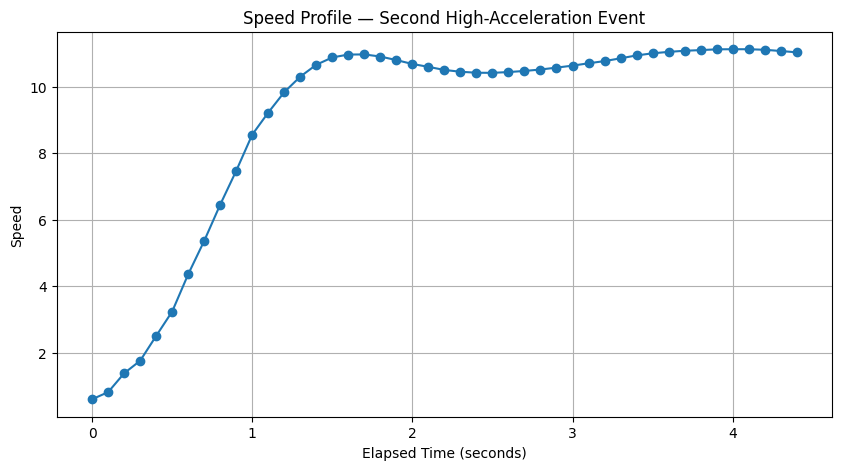

In [149]:
plt.figure(figsize=(10, 5))

plt.plot(
    second_event_data["elapsed_time"],
    second_event_data["s"],
    marker="o"
)

plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Speed")
plt.title("Speed Profile — Second High-Acceleration Event")
plt.grid(True)
plt.show()

**Speed Cross-Check of the Second High-Acceleration Event**

The speed profile of `Player 57256 (Attempt 2)` showed a rapid increase in speed during the early portion of the sprint, reaching approximately `11.0` before becoming relatively stable. This pattern was broadly consistent with the acceleration profile, in which acceleration rose rapidly to approximately `9.74` and then declined.

Although acceleration decreased after its peak, speed continued increasing for some time because acceleration remained positive. During the later phase, acceleration approached zero and speed became relatively stable.

The second candidate therefore did not exhibit an obvious isolated acceleration spike based on the visual inspection of its acceleration and speed profiles. This is consistent with our observation of the first candidate event. Both events remain in the dataset; the IQR flag alone is not sufficient justification for removing them.

### **Calculating the Time of Maximum Acceleration for Each Event**

`Question:` At what elapsed time does each event reach its maximum recorded acceleration?

`Why:` The maximum acceleration value tells us the magnitude of the peak, but not when it occurs. By calculating the elapsed time corresponding to the maximum acceleration for every event, we can examine the timing of acceleration peaks across the full sample of 174 events.

We will calculate the elapsed time relative to the beginning of each event, rather than using the absolute timestamp, because each player's recording starts at a different time.

In [150]:
# Create a list to store the peak acceleration timing for each event

peak_acceleration_timing = []

# Process each event separately
for event_id, group in wr_forty_data.groupby("event_id"):

    # Convert time to datetime and sort chronologically
    group = group.copy()
    group["time"] = pd.to_datetime(group["time"])
    group = group.sort_values("time")

    # Calculate elapsed time from the beginning of this event
    group["elapsed_time"] = (
        group["time"] - group["time"].min()
    ).dt.total_seconds()

    # Find the row where acceleration is maximum
    peak_row = group.loc[group["a"].idxmax()]

    # Store the information about this event's acceleration peak
    peak_acceleration_timing.append({
        "event_id": event_id,
        "nfl_id": peak_row["nfl_id"],
        "draft_year": peak_row["draft_year"],
        "attempt": peak_row["attempt"],
        "max_acceleration": peak_row["a"],
        "time_to_max_acceleration": peak_row["elapsed_time"]
    })

# Convert results into a DataFrame
peak_acceleration_timing = pd.DataFrame(peak_acceleration_timing)

peak_acceleration_timing.head()

,event_id,nfl_id,draft_year,attempt,max_acceleration,time_to_max_acceleration
0,20240302100700_1709410581872_000,57231,2024,1,6.314431,0.8
1,20240302100700_1709410633113_000,57201,2024,1,5.929191,0.8
2,20240302100700_1709410684796_000,57606,2024,1,5.489971,1.0
3,20240302100700_1709410743317_000,57154,2024,1,5.638890,0.8
4,20240302100700_1709410796245_000,57256,2024,1,4.938945,0.9


#### **Distribution of Time to Maximum Acceleration**

`Question:` At what point during the sprint do events generally reach their maximum acceleration, and how widely does this timing vary across the 174 events?

`Why:` The first few records suggest that maximum acceleration often occurs within approximately the first second. However, examining only a few events cannot establish the pattern across the full sample. A histogram will allow us to observe the distribution of peak-acceleration timing, identify where events are concentrated, and examine how much variation exists between events.

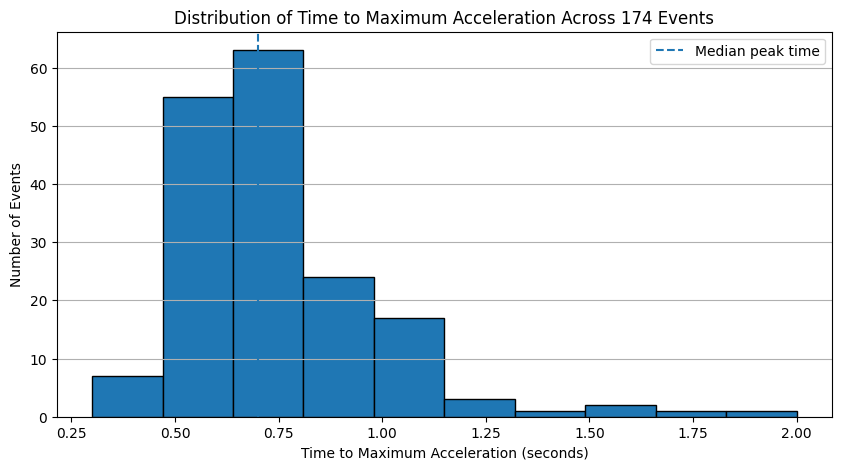

In [151]:
plt.figure(figsize=(10, 5))

plt.hist(
    peak_acceleration_timing["time_to_max_acceleration"],
    bins=10,
    edgecolor="black"
)

plt.axvline(
    peak_acceleration_timing["time_to_max_acceleration"].median(),
    linestyle="--",
    label="Median peak time"
)

plt.xlabel("Time to Maximum Acceleration (seconds)")
plt.ylabel("Number of Events")
plt.title("Distribution of Time to Maximum Acceleration Across 174 Events")
plt.legend()
plt.grid(axis="y")
plt.show()

**What the histogram tells us**
- Approximately 55 events have their maximum acceleration between 0.50–0.65 seconds.
- Approximately 60–65 events are concentrated between 0.65–0.80 seconds.
- Another group peaks around 0.80–1.10 seconds, but the frequency is lower.
- Only a few events reach their maximum acceleration after 1.2 seconds.
- A small number extend as late as roughly 2.0 seconds.

So the distribution is concentrated in the early part of the sprint, with a tail extending toward later peak times.

#### **Quantifying the Timing of Maximum Acceleration**

`Question:` What proportion of events reach their maximum acceleration within the first second, and what are the central values of peak-acceleration timing?

`Why:` The histogram suggests that maximum acceleration is concentrated in the early part of the sprint. Numerical summaries will help quantify this pattern, allowing us to report the median timing, variability, and proportion of events reaching peak acceleration within one second instead of relying only on visual estimates.

In [152]:
# Numerical summary of peak acceleration timing

timing = peak_acceleration_timing["time_to_max_acceleration"]

print("Number of events:", timing.count())
print("Mean:", timing.mean())
print("Median:", timing.median())
print("Q1:", timing.quantile(0.25))
print("Q3:", timing.quantile(0.75))
print("Minimum:", timing.min())
print("Maximum:", timing.max())

# Percentage of events reaching peak acceleration within 1 second
within_1_second = (timing <= 1.0).sum()

percentage_within_1_second = (
    within_1_second / timing.count() * 100
)

print("Events reaching peak within 1 second:", within_1_second)
print("Percentage:", percentage_within_1_second)

Number of events: 174
Mean: 0.7563218390804597
Median: 0.7
Q1: 0.6
Q3: 0.9
Minimum: 0.3
Maximum: 2.0
Events reaching peak within 1 second: 160
Percentage: 91.95402298850574


- `Median: 0.7 seconds` — the typical event reaches maximum acceleration quite early.
- `75% of events:` reach maximum acceleration at or before 0.9 seconds (Q3).
- `91.95%:` reach maximum acceleration within 1 second.
- `14 events (8.05%):` reach maximum acceleration after 1 second.
- `Maximum:` 2.0 seconds.

The mean `(0.756 s)` is slightly greater than the median `(0.7 s)`, suggesting the distribution is pulled somewhat toward later peak times by the relatively small number of events with later peaks.

**Our interpretation**
Across these `174 events`, maximum recorded acceleration is generally reached early in the `40-yard dash`. The distribution is concentrated in the first second, while a smaller number of events reach their maximum acceleration later.

This is a descriptive finding, not a claim that all athletes have the same acceleration mechanics. Also, these are 174 events—not necessarily 174 unique players, since players may have multiple attempts.

# **Defining NFL Performance for Our Study**

`Question`
What variables in our available data can meaningfully represent NFL performance among wide receivers, and which of these should we consider as the outcome of our research?

`Why`
Our research aims to investigate whether Combine movement characteristics are associated with future NFL performance. However, NFL performance can be measured in different ways, such as participation, playing opportunity, and on-field production. These measures represent different aspects of a player's career and should not be treated as interchangeable.

Before feature engineering or model development, we need to examine the available career-performance variables, understand what each represents, and determine which outcome(s) are suitable for our research question.

This investigation will help us define the target variable and subsequently determine whether our problem is regression, classification, or another type of analysis.

In [153]:
wr_analysis.columns.tolist()

['draft_year',
 'nfl_id',
 'combine_position',
 'combine_height',
 'combine_weight',
 'hand_size',
 'arm_length',
 'wing_span',
 'ten_yd_split',
 'forty',
 'vertical',
 'broad_jump',
 'three_cone',
 'short_shuttle',
 'bench_reps',
 'ngs_athleticism_score',
 'ngs_college_production_score',
 'ngs_final_score',
 'career_offensive_snaps',
 'career_defensive_snaps',
 'career_special_teams_snaps',
 'career_games_active',
 'career_games_started',
 'ap_all_pro_1st_team',
 'ap_all_pro_2nd_team',
 'pro_bowl_original_ballot',
 'nfl_position',
 'remaining_30yd_time']

## **Investigating NFL Career Participation Among Wide Receivers**

`Question`
How does NFL career participation vary among the wide receivers in our analysis dataset, particularly in terms of offensive snaps, games active, and games started?

`Why`
Career participation variables describe different aspects of a player's involvement in the NFL. Offensive snaps indicate playing involvement, games active indicate roster/game availability, and games started reflect a player's role. Examining their distributions, ranges, and zero values will help us understand the available career data and assess whether these variables could serve as meaningful measures of NFL performance in our study.

At this stage, we are exploring the variables rather than selecting a final outcome or defining a classification threshold.

In [154]:
# Examine the three particiation variables

participation_columns = [
    "career_offensive_snaps",
    "career_games_active",
    "career_games_started"
]

wr_analysis[participation_columns].describe()

,career_offensive_snaps,career_games_active,career_games_started
count,106.000000,106.000000,106.000000
mean,563.981132,22.226415,7.339623
std,659.355399,16.753839,10.358237
min,0.000000,0.000000,0.000000
25%,26.250000,9.750000,0.000000
50%,346.000000,17.000000,3.000000
75%,883.750000,34.000000,10.750000
max,2454.000000,51.000000,43.000000


**We have learned three things:**
1. All 106 WRs have values available for all three career participation variables.
2. Career participation varies considerably among players.
3. Offensive snaps and games started appear to have distributions where some players have substantially higher career totals than others.

### **Investigation: Visualizing NFL Career Participation**

`Question`
How are career offensive snaps, games active, and games started distributed among the 106 wide receivers?

`Why`
Our descriptive statistics showed substantial variation in career participation. The mean was higher than the median for all three variables, suggesting that some players may have considerably higher career totals than others.

Visualizing these distributions will help us examine their skewness, the concentration of values, and the presence of players with zero or unusually high career participation. This will give us a clearer understanding of these variables before deciding whether any of them could serve as an NFL performance outcome.

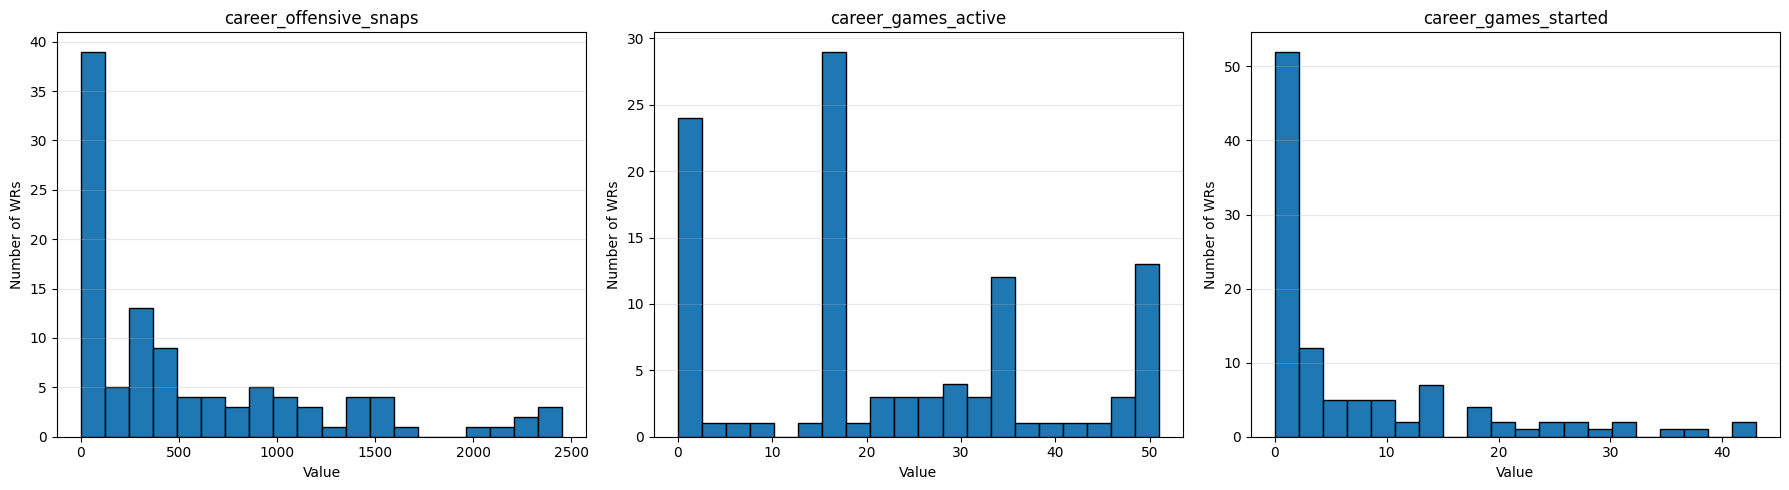

In [155]:


participation_columns = [
    "career_offensive_snaps",
    "career_games_active",
    "career_games_started"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, column in zip(axes, participation_columns):
    ax.hist(wr_analysis[column], bins=20, edgecolor="black")
    ax.set_title(column)
    ax.set_xlabel("Value")
    ax.set_ylabel("Number of WRs")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

`Graph 1 — career_offensive_snaps`
- Many WRs have relatively low snap counts.
- As snap counts increase, the number of players decreases.
- A few WRs have very high totals, reaching over 2,000 snaps.
- This distribution is strongly right-skewed.

`Graph 2 — career_games_active`
- Players are spread across different career participation levels.
- We see concentrations around low values, around the mid-teens, and at higher values.
- Some WRs have reached 40–50 games active.

`Graph 3 — career_games_started`
- More than half of the WRs appear to have very few starts or zero starts.
- A smaller group has substantially more starts.
- The distribution is right-skewed, with a long tail reaching above 40 starts.

**Our key observation:** career participation is not evenly distributed among these WRs. A small group has much higher career participation than many others.

But we should remember that career totals can depend on how long a player has been in the NFL. A player drafted earlier has had more opportunity to accumulate snaps, games, and starts than a recent draft class.

### **Investigation: Career Participation Across Draft Years**

`Question`
How do career participation measures differ across WR draft years (2023, 2024, and 2025)?

`Why`
Players drafted in different years have had different amounts of time to accumulate career statistics. Earlier draft classes may have had more opportunities to record offensive snaps, games active, and games started than more recent classes.

Comparing participation measures across draft years will help us understand how career exposure may influence these variables and whether direct comparisons of career totals could be misleading.

#### **Step 1 — Compare participation by draft year**

In [156]:
participation_columns = [
    "career_offensive_snaps",
    "career_games_active",
    "career_games_started"
]

wr_analysis.groupby("draft_year")[participation_columns].agg(
    ["mean", "median", "max"]
)

career_offensive_snaps              career_games_active             \
                             mean median   max                mean median max   
draft_year                                                                      
2023                   916.368421  687.0  2454           32.710526   39.0  51   
2024                   565.741935  367.0  1684           23.741935   28.0  35   
2025                   200.594595   58.0   787           10.189189   17.0  17   

           career_games_started             
                           mean median max  
draft_year                                  
2023                  11.842105    4.5  43  
2024                   7.741935    4.0  30  
2025                   2.378378    0.0  14

The pattern is consistent across all three measures: the earlier draft cohort has higher career participation totals than the more recent cohorts.
- 2023 WRs have the highest values.
- 2024 WRs are in the middle.
- 2025 WRs have the lowest values.

The same pattern appears in medians too, so it's not only a few very high-value players affecting the means.

### **Investigating Career Exposure and Participation Rates**

`Question`
How does career participation change when we account for the number of games a WR was active?

`Why`
Raw career totals are influenced by the amount of time a player has had to accumulate NFL experience. Comparing players using total offensive snaps alone may therefore favor earlier draft cohorts.

By examining participation relative to games active, we can explore measures such as offensive snaps per active game and starts relative to active games. These may provide a more comparable view of playing involvement, although they still do not measure receiving performance directly.

In [157]:
wr_analysis["snaps_per_active_game"] = (
    wr_analysis["career_offensive_snaps"] /
    wr_analysis["career_games_active"].replace(0, np.nan)
)

wr_analysis["start_rate"] = (
    wr_analysis["career_games_started"] /
    wr_analysis["career_games_active"].replace(0, np.nan)
)

In [158]:
wr_analysis[
    [
        "nfl_id",
        "draft_year",
        "career_offensive_snaps",
        "career_games_active",
        "career_games_started",
        "snaps_per_active_game",
        "start_rate"
    ]
].head(10)

,nfl_id,draft_year,career_offensive_snaps,career_games_active,career_games_started,snaps_per_active_game,start_rate
0,56056,2023,1022,38,11,26.894737,0.289474
1,56118,2023,334,30,0,11.133333,0.000000
2,55885,2023,2125,51,31,41.666667,0.607843
3,55920,2023,1190,30,20,39.666667,0.666667
4,56198,2023,0,0,0,NaN,NaN
5,56238,2023,0,0,0,NaN,NaN
6,56109,2023,558,40,1,13.950000,0.025000
7,56541,2023,325,21,2,15.476190,0.095238
8,56371,2023,0,0,0,NaN,NaN
9,56052,2023,1484,51,23,29.098039,0.450980


### **Examining Adjusted Career Participation Measures**

`Question:` How are offensive snaps per active game and the starting rate distributed across our wide receiver sample, and how many players have undefined values for these measures?

`Why:` We created these measures to reduce the influence of total career exposure. Before comparing them across draft years or considering them for further analysis, we need to examine their distributions, variability, and undefined values. This will help us determine whether they provide useful information about player participation and whether any limitations remain.

In [159]:
wr_analysis[["snaps_per_active_game", "start_rate"]].describe()

,snaps_per_active_game,start_rate
count,85.000000,85.000000
mean,22.069439,0.276391
std,14.528844,0.268576
min,0.117647,0.000000
25%,8.705882,0.034483
50%,21.588235,0.176471
75%,33.392857,0.454545
max,51.125000,0.934783


In [160]:
wr_analysis[["snaps_per_active_game", "start_rate"]].isna().sum()

snaps_per_active_game    21
start_rate               21
dtype: int64

### **Comparing Adjusted Career Participation Across Draft Years**

`Question`
Do offensive snaps per active game and starting rate differ across the 2023, 2024, and 2025 WR draft cohorts?

`Why`
Our previous investigation showed that raw career participation totals were substantially higher among earlier draft cohorts. We created adjusted participation measures to account partially for playing opportunity. Comparing these measures across draft years will help us examine whether cohort differences remain even after adjusting career totals relative to games active.

This comparison is exploratory. The adjusted measures still do not account for every difference in career exposure, player role, or opportunity.

In [161]:
wr_analysis.groupby("draft_year")[
    ["snaps_per_active_game", "start_rate"]
].agg(["mean", "median", "count"])

snaps_per_active_game                  start_rate                
                            mean     median count       mean    median count
draft_year                                                                  
2023                   25.173517  23.957172    32   0.318165  0.227451    32
2024                   21.624046  22.159502    28   0.289431  0.200980    28
2025                   18.595059  20.235294    25   0.208314  0.117647    25

## **Identifying NFL Production Variables**

`Question`
Which variables in the available NFL play-level data can represent actual on-field production for wide receivers, beyond career participation measures?

`Why`
Our previous investigations examined career participation measures such as offensive snaps, games active, and games started. Although these variables describe a player's involvement in the NFL, they do not directly measure receiving production.

To better address our research question, we need to identify variables that reflect actual on-field outcomes, such as receiving yards, receptions, touchdowns, or other relevant measures. Investigating the available play-level data will help us determine whether more meaningful performance outcomes can be constructed for our WR sample.

Before selecting a target variable or defining a classification problem, we must understand what production-related information is actually available and how it is recorded.

#  **Players Play Dataset ( investigation)**

In [171]:
player_play = pd.read_csv(
    data_dir / "player_play.csv",

)

player_play.columns.tolist()


['game_id',
 'play_id',
 'team_abbr',
 'nfl_id',
 'lined_up_position',
 'play_description',
 'quarter',
 'down',
 'yards_to_go',
 'possession_team',
 'yardline_side',
 'yardline_number',
 'game_clock',
 'pre_snap_home_score',
 'pre_snap_visitor_score',
 'play_direction',
 'pre_snap_home_team_win_probability',
 'pre_snap_visitor_team_win_probability',
 'home_team_win_probability_added',
 'visitor_team_win_probility_added',
 'expected_points_added',
 'expected_points',
 'offense_formation',
 'receiver_alignment',
 'pass_result',
 'pass_length',
 'play_nullified_by_penalty',
 'penalty_yards',
 'pre_penalty_yards_gained',
 'yards_gained',
 'team_coverage_man_zone',
 'team_coverage_type',
 'in_motion_at_ball_snap',
 'target',
 'rec_yards',
 'rush_yards',
 'yards_after_catch',
 'fumble',
 'fumble_lost',
 'route_ran',
 'separation_at_pass_forward',
 'cushion',
 'expected_yards_after_catch',
 'dropback_duration',
 'extended_sack_allowed',
 'pass_rushers_encountered',
 'peak_pressure_probabilit

### **Exploring Receiving-Related Variables in Play-Level Data**

`Question`
What information do the receiving-related variables in `player_play` contain, and how are they recorded for individual player-play observations?

`Why`
Before constructing NFL performance measures, we need to understand the meaning and structure of the available receiving-related variables. Examining individual records will help us distinguish targets, receptions, yardage outcomes, and other pass-related information, while avoiding assumptions about how these fields are recorded.

This investigation will guide our selection of meaningful NFL production measures for the wide receiver sample.

In [172]:
receiving_columns = [
    "nfl_id",
    "lined_up_position",
    "pass_result",
    "pass_length",
    "target",
    "rec_yards",
    "yards_gained",
    "yards_after_catch",
    "expected_yards_after_catch"
]

player_play[receiving_columns].head(10)

,nfl_id,lined_up_position,pass_result,pass_length,target,rec_yards,yards_gained,yards_after_catch,expected_yards_after_catch
0,57183,T,I,22.0,False,NaN,0,NaN,NaN
1,58248,INTERIOR_LINE,NaN,NaN,False,NaN,5,NaN,NaN
2,57140,EDGE,R,NaN,False,NaN,14,NaN,NaN
3,58209,T,NaN,NaN,False,NaN,4,NaN,NaN
4,57191,OLB,R,NaN,False,NaN,7,NaN,NaN
5,57606,SLOT_WR,I,16.0,False,NaN,0,NaN,NaN
6,57152,SLOT_WR,C,18.0,True,18.0,18,0.0,0.461675
7,58214,G,NaN,NaN,False,NaN,8,NaN,NaN
8,55976,T,IN,5.0,False,NaN,0,NaN,NaN
9,57434,INTERIOR_LINE,C,6.0,False,NaN,14,NaN,NaN


In [173]:
player_play.shape

(314197, 64)

#### **Investigating Missing Values in Receiving-Related Variables**

`Question:` How complete are the receiving-related variables in the `player_play` dataset, and how much missing information is present in each variable?

`Why:` Missing values may occur because a variable is not applicable to a particular play—for example, a receiving outcome may not exist for a rushing play. Therefore, we need to examine missingness before interpreting these variables or constructing performance measures. This will help us distinguish structurally expected missing values from missing information that may require further investigation.

In [174]:
player_play.info()

<class 'pandas.DataFrame'>
RangeIndex: 314197 entries, 0 to 314196
Data columns (total 64 columns):
 #   Column                                 Non-Null Count   Dtype  
---  ------                                 --------------   -----  
 0   game_id                                314197 non-null  int64  
 1   play_id                                314197 non-null  int64  
 2   team_abbr                              314197 non-null  str    
 3   nfl_id                                 314197 non-null  int64  
 4   lined_up_position                      312814 non-null  str    
 5   play_description                       314197 non-null  str    
 6   quarter                                314197 non-null  int64  
 7   down                                   314197 non-null  int64  
 8   yards_to_go                            314197 non-null  int64  
 9   possession_team                        314197 non-null  str    
 10  yardline_side                          310095 non-null  str    
 11

In [175]:
player_play[receiving_columns].isnull().sum()

nfl_id                             0
lined_up_position               1383
pass_result                   103636
pass_length                   129458
target                             0
rec_yards                     307937
yards_gained                       0
yards_after_catch             307937
expected_yards_after_catch    305221
dtype: int64

In [176]:
(player_play[receiving_columns].isnull().mean() * 100).round(2)

nfl_id                         0.00
lined_up_position              0.44
pass_result                   32.98
pass_length                   41.20
target                         0.00
rec_yards                     98.01
yards_gained                   0.00
yards_after_catch             98.01
expected_yards_after_catch    97.14
dtype: float64

#### **Investigating Missing Receiving Outcomes Among Targeted Players**

`Question:` Are the missing receiving outcome variables primarily associated with player-play records where the player was not targeted?

`Why:` Receiving statistics are not applicable to every player-play observation. A player may participate in a play without being the intended receiver. By using the target indicator, we can distinguish non-targeted records from targeted records and investigate whether the missing receiving outcomes are structurally expected or require further examination.

In [177]:
player_play["target"].value_counts()

target
False    304355
True       9842
Name: count, dtype: int64

#### **Examining Missing Receiving Outcomes Among Targeted Records**

`Question:` Among player-play records marked as targeted, how many have missing receiving outcome variables?

`Why:` Overall missingness can be misleading because the dataset contains many records where a player was not targeted. Restricting the analysis to targeted records allows us to examine the completeness of receiving outcomes within the subset most relevant to receiver performance. This will help us understand whether missing values are explained by non-targeted plays or remain present among targeted observations.

In [178]:
targeted_plays = player_play[player_play["target"] == True]

targeted_plays[
    ["rec_yards", "yards_after_catch", "expected_yards_after_catch"]
].isnull().sum()

rec_yards                     3586
yards_after_catch             3586
expected_yards_after_catch     866
dtype: int64

#### **Investigating Pass Outcomes Among Targeted Records**

`Question:` What pass outcomes occur among targeted player-play records, and how do these outcomes relate to the availability of receiving statistics?

`Why:` A targeted player may be involved in different pass outcomes, not only completed receptions. Examining the pass-result categories alongside receiving statistics will help us understand why some targeted records have receiving values while others do not. This is important before deciding which records can be used to construct receiver-performance measures.

In [179]:
targeted_plays["pass_result"].value_counts(dropna=False)

pass_result
C     6256
I     3319
IN     267
Name: count, dtype: int64

#### **Examining Receiving-Yard Availability Across Pass Outcomes**

`Question:`  How does the availability of receiving-yard data differ across completed, incomplete, and intercepted passes?

`Why:` Comparing receiving-yard availability across pass outcomes will help us understand whether missing receiving statistics are associated with the outcome of the pass. This is an important step in evaluating whether missing values are structurally expected or whether they remain unexplained within particular outcome categories.

In [181]:
targeted_plays.groupby("pass_result").agg(
    total_records=("rec_yards", "size"),
    missing_records=("rec_yards", lambda x: x.isna().sum()),
    available_records=("rec_yards", "count")
)

,total_records,missing_records,available_records
pass_result,,,
C,6256,0,6256
I,3319,3319,0
IN,267,267,0


#### **Receiving-yard distribution among completed passes**

`Question:` Among completed targeted passes, how are receiving yards distributed?

`Why:` Now that we have confirmed receiving yards are available for completed passes (C), we should restrict our analysis to completed receptions. Including incomplete and intercepted passes would introduce records where receiving yards are not applicable.

In [ ]:
# Create a completed-pass subset

completed_passes = targeted_plays[
    targeted_plays["pass_result"] == "C"     # checks which rows represent completed passes.
].copy()

completed_passes.shape

(6256, 64)

##### **Examine the receiving-yard distribution**

`Question`
What does the distribution of receiving yards look like among completed passes?

`Why?`
We want to understand typical receiving-yard values, variability, unusually large gains, and whether the distribution is skewed. This helps us decide which visualization and analysis are appropriate next.

In [183]:
completed_passes["rec_yards"].describe()

count    6256.000000
mean       12.018702
std        10.452609
min       -11.000000
25%         5.000000
50%         9.000000
75%        16.000000
max        93.000000
Name: rec_yards, dtype: float64

##### **Investigate negative receiving-yard records**

`Question:` Are negative receiving-yard values isolated cases, or do they occur across multiple completed passes?

`Why?` A negative value could be a legitimate play—for example, a receiver catches a pass behind the line of scrimmage and is tackled for a loss. We should investigate the actual records before treating them as data errors.

In [184]:
# Count negative-yard receptions

negative_rec_yards = completed_passes[
    completed_passes["rec_yards"] < 0
]

negative_rec_yards.shape

(134, 64)

In [185]:
# Inspect the actual plays

negative_rec_yards[
    [
        "game_id",
        "play_id",
        "play_description",
        "pass_result",
        "pass_length",
        "yards_gained",
        "rec_yards"
    ]
].head(10)

,game_id,play_id,play_description,pass_result,pass_length,yards_gained,rec_yards
7256,2025100502,840,"(:01) (No Huddle, Shotgun) T.Tagovailoa pass s...",C,-3.0,-5,-5.0
8394,2025090703,1440,(6:13) (Shotgun) B.Young pass short left to X....,C,-1.0,-1,-1.0
11942,2023081851,164,(13:08) (Shotgun) D.Jones pass short middle to...,C,-4.0,-3,-3.0
13233,2024081852,1355,(10:12) (Shotgun) J.Dobbs pass short left to J...,C,-5.0,-5,-5.0
13234,2024112402,3308,(11:24) C.Stroud pass short left to C.Stover t...,C,-4.0,-4,-4.0
15197,2024092906,242,(13:39) (Shotgun) B.Nix pass short right to T....,C,-4.0,-4,-4.0
17184,2025090800,2450,(8:54) C.Williams pass short right to L.Burden...,C,-5.0,-3,-3.0
17648,2025092104,4005,(1:07) (Shotgun) D.Maye pass short left to D.D...,C,0.0,-1,-1.0
20223,2025082356,853,(2:38) (Shotgun) S.Clifford pass short right t...,C,-1.0,-1,-1.0
20290,2025010514,2938,(5:53) (Shotgun) B.Mayfield pass short middle ...,C,-5.0,-6,-6.0


##### **How are the negative values distributed?**

We know there are `134 negative-yard` receptions. Now let's check which negative yard values occur most frequently.

`Question` Are most losses small (−1, −2, −3 yards), or are larger losses also common?

In [186]:
negative_rec_yards["rec_yards"].value_counts().sort_index()

rec_yards
-11.0     1
-9.0      1
-8.0      2
-7.0      1
-6.0      4
-5.0      9
-4.0     19
-3.0     19
-2.0     28
-1.0     50
Name: count, dtype: int64

#### **Visualize the overall receiving-yard distribution**

`Question`
How are receiving yards distributed across all completed passes?

`Why?`
The summary statistics suggested that the `mean (12.02 yards)` is higher than the `median (9 yards)`. A histogram will help us visually examine:
- where most receptions fall,
- whether the distribution is right-skewed,
- how frequent large gains are,
- and how negative-yard receptions fit into the overall distribution.

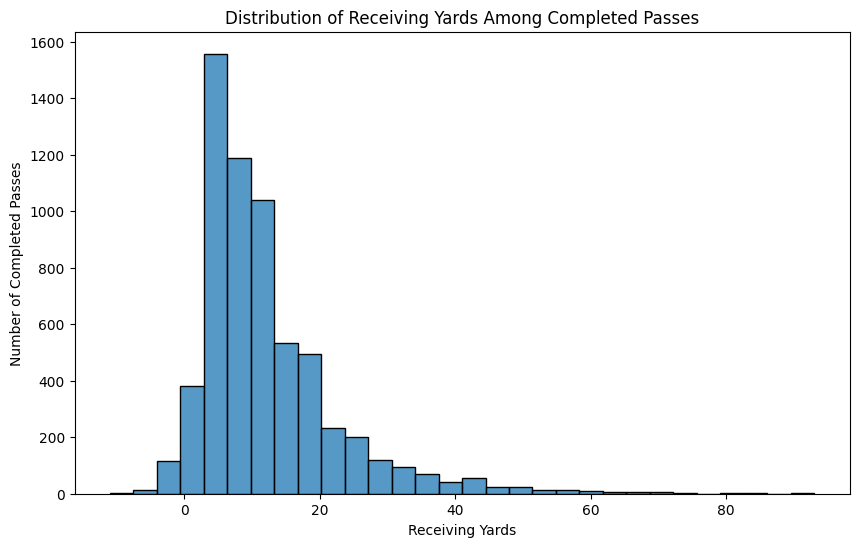

In [187]:

plt.figure(figsize=(10, 6))

sns.histplot(
    data=completed_passes,
    x="rec_yards",
    bins=30
)

plt.title("Distribution of Receiving Yards Among Completed Passes")
plt.xlabel("Receiving Yards")
plt.ylabel("Number of Completed Passes")

plt.show()

##### **Examine receiving-yard spread and potential outliers**
W
e have already used a histogram to understand frequency. Now let's use a boxplot to examine the spread of receiving yards and identify values that may be statistically unusual.

`Question`
How spread out are receiving-yard outcomes, and are there unusually large gains relative to the typical reception?

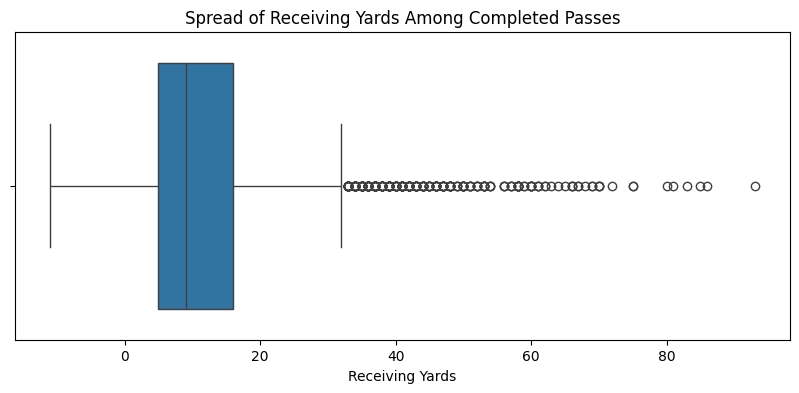

In [188]:
plt.figure(figsize=(10, 4))

sns.boxplot(data=completed_passes, x="rec_yards")

plt.title("Spread of Receiving Yards Among Completed Passes")
plt.xlabel("Receiving Yards")

plt.show()

 **Observation**

The boxplot shows a number of observations beyond the upper whisker, indicating unusually high receiving-yard gains relative to the central distribution. These observations are consistent with the right-skewed distribution observed in the histogram. However, statistical outliers are not necessarily erroneous records; they may represent legitimate explosive plays. Therefore, these observations will be retained unless further investigation identifies data-quality issues.

### **Understanding negative receiving yards**

`Question`
Why do some completed passes result in negative receiving yards, and what types of plays are represented by these observations?

In [189]:
# Examine the characteristics of negative-yard completed passes

negative_rec_yards[
    ["play_description", "pass_length", "yards_gained", "rec_yards"]
].head(15)

,play_description,pass_length,yards_gained,rec_yards
7256,"(:01) (No Huddle, Shotgun) T.Tagovailoa pass s...",-3.0,-5,-5.0
8394,(6:13) (Shotgun) B.Young pass short left to X....,-1.0,-1,-1.0
11942,(13:08) (Shotgun) D.Jones pass short middle to...,-4.0,-3,-3.0
13233,(10:12) (Shotgun) J.Dobbs pass short left to J...,-5.0,-5,-5.0
13234,(11:24) C.Stroud pass short left to C.Stover t...,-4.0,-4,-4.0
15197,(13:39) (Shotgun) B.Nix pass short right to T....,-4.0,-4,-4.0
17184,(8:54) C.Williams pass short right to L.Burden...,-5.0,-3,-3.0
17648,(1:07) (Shotgun) D.Maye pass short left to D.D...,0.0,-1,-1.0
20223,(2:38) (Shotgun) S.Clifford pass short right t...,-1.0,-1,-1.0
20290,(5:53) (Shotgun) B.Mayfield pass short middle ...,-5.0,-6,-6.0


**Compare the three variables systematically**

Instead of inspecting only `15 plays`, let's examine all `134 negative-reception-yard plays`.`

In [190]:
negative_rec_yards[
    ["pass_length", "yards_gained", "rec_yards"]
].corr()

,pass_length,yards_gained,rec_yards
pass_length,1.000000,0.257594,0.392372
yards_gained,0.257594,1.000000,0.830253
rec_yards,0.392372,0.830253,1.000000


#### **Pass length and negative receiving yards**

`Question`
Are negative receiving-yard outcomes concentrated among short passes, or do they occur across different pass lengths?

`Why?`
We have identified 134 completed passes with negative receiving yards. So far, we have examined the yardage values themselves, the play descriptions, and the correlation between pass_length, yards_gained, and rec_yards.

In [191]:
# Examine the distribution of pass_length

negative_rec_yards["pass_length"].value_counts().sort_index()

pass_length
-9.0     2
-8.0     2
-7.0     2
-6.0     6
-5.0    23
-4.0    31
-3.0    35
-2.0    20
-1.0     7
 0.0     3
 1.0     1
 2.0     1
 3.0     1
Name: count, dtype: int64

**We've examined the values, but now we should see whether the negative receiving-yard records are concentrated in a particular range of pass_length.**

A simple visualization will help us see the distribution more clearly.

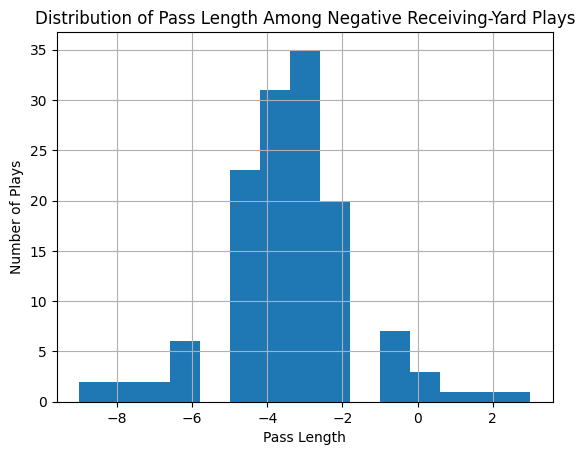

In [192]:
negative_rec_yards["pass_length"].hist(bins=15)

plt.title("Distribution of Pass Length Among Negative Receiving-Yard Plays")
plt.xlabel("Pass Length")
plt.ylabel("Number of Plays")
plt.show()

**Observation**

The distribution of pass length among plays with negative receiving yards is concentrated primarily around `-4 to -3` yards, with most observations falling within the broader range of approximately `-5 to -2` yards. The distribution is spread across multiple values, while a few extreme negative pass lengths `(such as -8 and -9 yards)` occur relatively infrequently. Small positive pass-length values are also present but appear isolated.

This suggests that negative receiving-yard plays in our sample are often associated with short pass lengths, although the distribution alone does not establish the specific circumstances behind these plays.

#### **investigating: `rec_yards` vs `yards_gained`**

We have two columns describing yard-related outcomes in these plays. Let's investigate whether they record the same value in negative-yard plays, or whether they differ.

In [ ]:
# Compare two variables

negative_rec_yards[["yards_gained", "rec_yards"]].describe()

,yards_gained,rec_yards
count,134.000000,134.000000
mean,-2.552239,-2.619403
std,2.445088,1.871009
min,-12.000000,-11.000000
25%,-4.000000,-4.000000
50%,-2.000000,-2.000000
75%,-1.000000,-1.000000
max,14.000000,-1.000000


**Find records where they differ**

`Why?` We want to inspect actual plays where the two values differ. The summary statistics tell us that they differ, 
but individual records may help us understand how.

In [ ]:


negative_rec_yards[
    negative_rec_yards["yards_gained"] != negative_rec_yards["rec_yards"]
][["play_description", "yards_gained", "rec_yards"]].head(15)

,play_description,yards_gained,rec_yards
152947,(:02) (Shotgun) B.Young pass short right to J....,-12,-11.0
188281,(:44) (Shotgun) B.Young pass short middle to X...,-9,-4.0
205667,(2:58) (Shotgun) B.Nix pass short right to M.M...,14,-1.0


**Examine the complete descriptions of these 3 plays**

`Why?` The earlier output truncated the descriptions. We want to read the full play text and see whether the descriptions offer any clues about what happened.

In [195]:
pd.set_option("display.max_colwidth", None)

negative_rec_yards[
    negative_rec_yards["yards_gained"] != negative_rec_yards["rec_yards"]
][["play_description", "pass_length", "yards_gained", "rec_yards", "pass_result"]]

,play_description,pass_length,yards_gained,rec_yards,pass_result
152947,"(:02) (Shotgun) B.Young pass short right to J.Coker to CAR 37 for 2 yards. FUMBLES, touched at CAR 24, RECOVERED by NO-P.Werner at CAR 23.",-3.0,-12,-11.0,C
188281,"(:44) (Shotgun) B.Young pass short middle to X.Legette to DAL 39 for -3 yards (R.Steward). FUMBLES (R.Steward), recovered by CAR-R.Dowdle at DAL 40. R.Dowdle to DAL 41 for -1 yards (D.Ezeiruaku). FUMBLES (D.Ezeiruaku), touched at DAL 41, recovered by CAR-X.Legette at DAL 45.",3.0,-9,-4.0,C
205667,"(2:58) (Shotgun) B.Nix pass short right to M.Mims to DEN 47 for -1 yards (C.Barton).\r\r\nPENALTY on TEN-J.Simmons, Unnecessary Roughness, 15 yards, enforced at DEN 47.",-3.0,14,-1.0,C


`Investigation` Let's test whether fumbles and penalties are common among all 134 negative receiving-yard plays, rather than relying only on the three differing records.

`Why?`
This checks how many of our 134 negative-reception-yard plays contain a mention of a fumble or penalty in the play description.

In [196]:
negative_rec_yards["play_description"].str.contains(
    "FUMBLES|PENALTY",
    case=False,
    na=False
).value_counts()

play_description
False    125
True       9
Name: count, dtype: int64

So, approximately 6.7% of the negative receiving-yard plays contain a mention of FUMBLES or PENALTY in their descriptions, while 125 plays (93.3%) do not contain either keyword.

`**Separate fumbles from penalties**`

Right now, our search combines both keywords. We don't know how many are fumbles and how many are penalties (some plays may contain both).

`Why?`

We want to distinguish two possible explanations instead of treating them as one category:
- `Fumbles` → possession changes or recovery situations.
- `Penalties` → additional yardage adjustments or enforcement situations.

In [197]:
negative_rec_yards["play_description"].str.contains(
    "FUMBLES", case=False, na=False
).sum()

np.int64(5)

In [198]:
negative_rec_yards["play_description"].str.contains(
    "PENALTY", case=False, na=False
).sum()

np.int64(4)

**Observation**

Among the `134 plays` with negative receiving yards, 5 play descriptions contain the keyword `FUMBLES` and 4 contain `PENALTY`. In total, 9 plays (approximately 6.7%) contain either keyword, while 125 plays do not.

These keyword-based counts suggest that fumbles and penalties are present but account for a relatively small portion of the subset. However, the search is based on text descriptions and should not be treated as a complete classification of play events.

In [199]:
# inspect all 9 flagged plays together so we can see what they actually contain, rather than just counting keywords.

negative_rec_yards[
    negative_rec_yards["play_description"].str.contains(
        "FUMBLES|PENALTY", case=False, na=False
    )
][["play_description", "pass_length", "yards_gained", "rec_yards"]]

,play_description,pass_length,yards_gained,rec_yards
11942,"(13:08) (Shotgun) D.Jones pass short middle to J.Hyatt to CAR 47 for -3 yards (J.Chinn). Penalty on NYG-A.Thomas, Illegal Block Above the Waist, declined.",-4.0,-3,-3.0
40564,"(12:13) (Shotgun) P.Mahomes pass short left to R.Rice to KC 21 for -1 yards (R.Darby). FUMBLES (R.Darby), ball out of bounds at KC 21.",-3.0,-1,-1.0
67674,"(4:04) (Shotgun) D.Mills pass short left to J.Noel to HST 48 for -1 yards (J.Jones).\r\r\nPenalty on HST-N.Collins, Offensive Pass Interference, declined.",-2.0,-1,-1.0
144758,"(11:48) (Shotgun) D.Maye pass short middle to D.Douglas to NE 29 for -1 yards (N.Igbinoghene) [J.Hollins]. Penalty on NE-C.Okorafor, Illegal Formation, declined.",1.0,-1,-1.0
152947,"(:02) (Shotgun) B.Young pass short right to J.Coker to CAR 37 for 2 yards. FUMBLES, touched at CAR 24, RECOVERED by NO-P.Werner at CAR 23.",-3.0,-12,-11.0
188281,"(:44) (Shotgun) B.Young pass short middle to X.Legette to DAL 39 for -3 yards (R.Steward). FUMBLES (R.Steward), recovered by CAR-R.Dowdle at DAL 40. R.Dowdle to DAL 41 for -1 yards (D.Ezeiruaku). FUMBLES (D.Ezeiruaku), touched at DAL 41, recovered by CAR-X.Legette at DAL 45.",3.0,-9,-4.0
205667,"(2:58) (Shotgun) B.Nix pass short right to M.Mims to DEN 47 for -1 yards (C.Barton).\r\r\nPENALTY on TEN-J.Simmons, Unnecessary Roughness, 15 yards, enforced at DEN 47.",-3.0,14,-1.0
236088,"(6:30) M.Stafford pass short left to P.Nacua to PHI 45 for -2 yards (J.Sweat). FUMBLES (J.Sweat), touched at LA 48, recovered by LA-C.Kupp at LA 48.",-2.0,-9,-9.0
245009,"(:50) (Shotgun) M.Jones sacked at ATL 44 for -8 yards (L.Floyd). FUMBLES (L.Floyd) [L.Floyd], recovered by SF-C.Colby at ATL 44.\r\r\nThe Replay Official reviewed the fumble ruling, and the play was REVERSED.\r\r\n(Shotgun) M.Jones pass short middle to C.Colby to ATL 37 for -1 yards (B.Dorlus, J.Bertrand) [L.Floyd].",-6.0,-1,-1.0


**Observation**

8 of the 9 plays containing fumbles are associated with Shotgun formations.

However, we shouldn't conclude that Shotgun causes negative-yard receptions or fumbles. We only examined the 134 negative-yard plays, not all Shotgun plays.

### **Examine the play descriptions of all 134 negative-yard plays more systematically.**

`Question`
What types of situations or play events appear in negative receiving-yard plays?

`Why?`
We want to determine whether negative receiving-yard plays are mostly ordinary short receptions, or whether a subset involves special circumstances such as fumbles, penalties, sacks, or other recorded events.

In [200]:
# inspect the descriptions systematically

negative_rec_yards["play_description"].value_counts().head(20)

play_description
(:01) (No Huddle, Shotgun) T.Tagovailoa pass short middle to M.Washington to CAR 10 for -5 yards (A.Robinson).                                                1
(6:13) (Shotgun) B.Young pass short left to X.Legette pushed ob at CAR 37 for -1 yards (T.Campbell).                                                          1
(13:08) (Shotgun) D.Jones pass short middle to J.Hyatt to CAR 47 for -3 yards (J.Chinn). Penalty on NYG-A.Thomas, Illegal Block Above the Waist, declined.    1
(10:12) (Shotgun) J.Dobbs pass short left to J.Cowing to NO 42 for -5 yards (R.Wright).                                                                       1
(11:24) C.Stroud pass short left to C.Stover to TEN 47 for -4 yards (R.McCreary).                                                                             1
(13:39) (Shotgun) B.Nix pass short right to T.Franklin to NYJ 44 for -4 yards (D.Reed).                                                                       1
(8:54) C.Williams pass 

#### **Quantify Shotgun prevalence**

`Question`
How many negative-reception-yard plays occurred from Shotgun versus non-Shotgun formations?

`Why?`
We have noticed Shotgun repeatedly. Now we need to determine whether that observation holds across the entire subset, rather than just the descriptions shown.

In [201]:
negative_rec_yards["play_description"].str.contains(
    "Shotgun", case=False, na=False
).value_counts()

play_description
True     109
False     25
Name: count, dtype: int64